<a href="https://colab.research.google.com/github/junseo25/ds2002-walmart-hurricane-project/blob/main/notebooks/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics | Combined Working Notebook
Team: Mark Chernov, Michael Tague, Jun Seo Lee (J.S.)

## 1. Imports and configuration
## 2. Load and inspect the data
## 3. Cleaning functions and decision log
## 4. Validate the cleaned tables
## 5. Weather retrieval and validated joins
## 6. Q1 — Category demand surge
## 7. Q2 — Pop-Tarts consolidation
## 8. Q3 — Weather relationships and lag
## 9. Q4 — Store geography
## 10. Q5 — Board-game investigation
## 11. Data visualizations for the presentation
## 12. Recommendation
## 13. Final reflections
## 14. Sources and final checks

##1. Imports and Configuration

These code cells have our team setup and imports the libraries and defines common data sources used throughout the notebook alongside dates, baseline, API settings.

---



###1.1 Team Setup
Source: October 23 Midterm Checkpoint notebook

Records team members, project links, and team setup checks

In [419]:
team_setup = {
    'team_name': 'TaLeCh',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Mark Chernov', 'github': 'https://github.com/MarkChernov123'},
        {'name': 'Michael Tague', 'github': 'https://github.com/michaeltague6'},
        {'name': 'JS ', 'github': 'https://github.com/junseo25'},
    ],
    'repo_url': 'https://github.com/junseo25/ds2002-walmart-hurricane-project/tree/main',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/junseo25/ds2002-walmart-hurricane-project/blob/main/TEAM_CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'JS',           # nice to have
    'meeting_time': 'Tuesday 7-8:30',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['structuring the data in a way that is legible', 'future proof the code', 'not encountering errors with open-meteo API keys(even though they are not needed for past data)', 'cleaning the data using the correct steps without any errors compounding.', 'Being wrong in what the next correct step in cleaning is'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

###1.2 Imports
Source: Combined from multiple notebooks

Loads the libraries used for data processing, charts, weather requests, database queries, and file paths.

In [420]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import requests
import time
import sqlite3
import urllib.request
from datetime import datetime, timedelta
from pathlib import Path
import requests as requests, time
from urllib.parse import urlencode
from datetime import date, timedelta

##2. Load and inspect the five data files

Loads the transaction, product, store, distribution-center, and SQLite files, including both database tables. Reports data types, missing values, duplicates, and source fingerprints before cleaning.

###2.1 Load the four CSV files
Source: Weather_cleaning3.ipynb and Weather_cleaning4.ipynb

Reads the four CSV files into separate DataFrames.

In [421]:
# providing a base URL to our Data folder and then specific directions to each individual dataset file
# Omitting "Inventory and Sales" for right now because it is a different file type
base_url = "https://raw.githubusercontent.com/junseo25/ds2002-walmart-hurricane-project/main/data"

transactions = pd.read_csv(f"{base_url}/walmart_transactions.csv")

product = pd.read_csv(f"{base_url}/product_catalog.csv")

store = pd.read_csv(f"{base_url}/store_locations.csv")

distribution = pd.read_csv(f"{base_url}/distribution_centers.csv")


###2.2 Load the SQLite Database
Source: DS_2002_Midterm_Project_Data_Cleaning Version 3.ipynb

Downloads the database and reads its two tables into DataFrames.

In [422]:
db_url = f"{base_url}/inventory_and_sales.db"
db_filepath = "inventory_and_sales.db"

try:
    urllib.request.urlretrieve(db_url, db_filepath)
    print("Database downloaded successfully!")
except Exception as e:
    print(f"Error downloading database: {e}")

# Connect to the database and read its tables.
conn = sqlite3.connect(db_filepath)

daily_sales = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary",
    conn
)

inventory_levels = pd.read_sql_query(
    "SELECT * FROM inventory_levels",
    conn
)

conn.close()

# Display sample records.
print("inventory_levels:")
display(inventory_levels.head())

print("daily_sales:")
display(daily_sales.head())

Database downloaded successfully!
inventory_levels:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


daily_sales:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30


###2.3 Inspect all loaded tables

Reports the row count, exact duplicates, and total missing values for each table.

In [423]:
#Creating a dictionary first
datasets = {
    "transactions": transactions,
    "product": product,
    "store": store,
    "distribution": distribution
}

# defining rows, duplicates, and missing values for all four files
for name, data in datasets.items():
    print(f"Dataset: {name}")
    print(f"Rows: {len(data)}")
    print(f"Duplicates: {data.duplicated().sum()}")
    print(f"Missing Values: {data.isnull().sum().sum()}")

Dataset: transactions
Rows: 25562
Duplicates: 30
Missing Values: 886
Dataset: product
Rows: 45
Duplicates: 0
Missing Values: 18
Dataset: store
Rows: 14
Duplicates: 0
Missing Values: 2
Dataset: distribution
Rows: 5
Duplicates: 0
Missing Values: 1


##3. Cleaning functions and decision log
Contains data cleaning, mapping, and timestamp functions.

###3.1 Clean the product catalog

Standardize product names, related SKUs, and clean the catalog's descriptive fields.

In [424]:
# Define products_clean by creating a copy of the raw product DataFrame
products_clean = product.copy()
products_clean["original_sku"] = products_clean["sku"]

###3.2 Standardize formatting and applies mapping



In [425]:
# Standardizing product formatting while replacing underscores with spaces, preserving word separations, and capitalizing
products_clean['product_name'] = (
    products_clean['product_name']
    .str.lower()
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('_', ' ', regex=False)  # Replaces underscores with a single space
    .str.replace('pk', '-pack', regex=False)
    .str.replace('sz', 'size', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace(r'\s+', ' ', regex=True)  # Condenses any multiple spaces into a single space
    .str.strip()
    .str.title()
    .str.replace('Aa', 'AA', regex=False)  # 2. Convert 'Aa' to 'AA' last so title() doesn't overwrite it
)

#Creating a product map - Logic: Put the Product Type first, then quantity (if applicable)
PRODUCT_MAP = {'Strawberry Pop-Tart': 'Pop-Tarts Strawberry',
            'Strawberry Pop-Tart': 'Pop-Tarts Strawberry',
            'Water - 24 Pack': 'Bottled Water 24-Pack',
            'Batteries AA 4-Pack': 'AA Batteries 4-Pack',
            'Board Game - Monopoly': 'Monopoly Board Game',
            'Streaming Device': 'Roku Streaming Stick',
            'Soup - Canned': 'Canned Soup',
            'Portable Phone Charger': 'Portable Charger',
            'Variety Pack - Chips': 'Chips Variety Pack',
            'Toilet Paper 12-Roll': 'Toilet Paper 12-Pack',
            'Baby Diapers - Size 3': 'Diapers Size 3',
            'Infant Formula': 'Baby Formula',
            'Tarp - Heavy Duty': 'Heavy Duty Tarp',
            'First-Aid Kit': 'First Aid Kit',
            'Flashlight Led': 'LED Flashlight',
            'Candles Emergency': 'Emergency Candles'
}
#applying the mapping
products_clean["product_name"] = (
    products_clean["product_name"].replace(PRODUCT_MAP)
)
print(products_clean["product_name"].unique())

['Pop-Tarts Strawberry' 'Bottled Water 24-Pack' 'AA Batteries 4-Pack'
 'LED Flashlight' 'Light Beer 24-Pack' 'Monopoly Board Game'
 'Playing Cards' 'Roku Streaming Stick' 'Canned Soup' 'White Bread'
 'Peanut Butter' 'Emergency Candles' 'First Aid Kit' 'Portable Charger'
 'Chips Variety Pack' 'Paper Towels' 'Toilet Paper 12-Pack'
 'Diapers Size 3' 'Baby Formula' 'Heavy Duty Tarp']


###3.3 Applies product-to-supplier mapping and displays resulting supplier assignments

In [426]:
# 1. Create a clean dictionary mapping standardized product names to their correct suppliers
PRODUCT_TO_SUPPLIER = {
    'Pop-Tarts Strawberry': "Kellogg's",
    'Bottled Water 24-Pack': 'Nestle',
    'AA Batteries 4-Pack': 'Duracell',
    'Flashlight Led': 'Everactive',
    'Light Beer 24-Pack': 'Anheuser-Busch',
    'Monopoly Board Game': 'Hasbro',
    'Playing Cards': 'Bicycle',
    'Roku Streaming Stick': 'Roku Inc',
    'Canned Soup': "Campbell's",
    'White Bread': 'Sara Lee',
    'Peanut Butter': 'J.M. Smucker',
    'Emergency Candles': 'Sterno',
    'First Aid Kit': 'Johnson & Johnson',
    'Portable Charger': 'Anker',
    'Chips Variety Pack': 'Frito-Lay',
    'Paper Towels 6-Pack': 'Georgia-Pacific',
    'Toilet Paper 12-Pack': 'Kimberly-Clark',
    'Diapers Size 3': 'Procter & Gamble',
    'Baby Formula': 'Abbott',
    'Heavy Duty Tarp': 'Tarps Plus'
}

# 2. Map the correct supplier onto the products_clean DataFrame using product_name
products_clean['supplier'] = products_clean['product_name'].map(PRODUCT_TO_SUPPLIER).fillna(products_clean['supplier'])

# 3. Display the standardized mapping table
supplier_mapping_df = products_clean[['product_name', 'supplier']].drop_duplicates().sort_values('product_name')
display(supplier_mapping_df)

,product_name,supplier
7,AA Batteries 4-Pack,Duracell
41,Baby Formula,Abbott
4,Bottled Water 24-Pack,Nestle
21,Canned Soup,Campbell's
33,Chips Variety Pack,Frito-Lay
39,Diapers Size 3,Procter & Gamble
27,Emergency Candles,Sterno
29,First Aid Kit,Johnson & Johnson
43,Heavy Duty Tarp,Tarps Plus
10,LED Flashlight,Frito-Lay


###3.4 Map product SKUs to canonical identifiers

In [427]:
# Moving onto a SKU map - logic: give the most info possible in each SKU
SKU_MAP = {'PT-12': 'POPTART-STRAW',
           'SKU#459812': 'POPTART-STRAW',
           'PT_STRAWBERRY': 'POPTART-STRAW',
           'WTR-24': 'WATER24PK',
           'WTR_24PK': 'WATER24PK',
           'BATT-100': 'BATT_AA_4PK',
           'BAT-AA4': 'BATT_AA_4PK',
           'FLASH-01': 'LED-FLASH',
           'BEER-24': 'LTBEER24',
           'BG-MONO': 'GAME-MONO',
           'MONOPOLY-01': 'GAME-MONO',
           'PLAY-CARD': 'PLAYCARD',
           'CARDS-01': 'PLAYCARD',
           'PLAYCARD-STD': 'PLAYCARD',
           'ROKU-STD': 'ROKUSTREAM',
           'STREAM-01': 'ROKUSTREAM',
           'CNSOUP-01': 'SOUP-CAN',
           'BREAD-WH': 'WHITEBREAD',
           'PNUTBTR-16': 'PEANUTBTR',
           'PB-16': 'PEANUTBTR',
           'CNDL-EM': 'CANDLE-EMRG',
           'FAID-01': 'FIRSTAID-KIT',
           'CHRG-PORT': 'PORTCHARGER',
           'CHIPS-VP': 'CHIPVARIETY',
           'PTOWEL-6': 'PAPERTOWEL',
           'PAPERTOWEL6': 'PAPERTOWEL',
           'TP-12': 'TOILETPAPER12',
           'DIAP-S3': 'DIAPERS-S3',
           'DIAPERS-3': 'DIAPERS-S3',
           'BFORM-01': 'BABYFORMULA',
           'HDTARP-01': 'TARP-HD',
}

products_clean["canonical_sku"] = (
    products_clean["sku"].replace(SKU_MAP)
)

###3.5 Convert unit_cost to numeric

In [428]:
# first making sure unit_cost is numeric
products_clean['unit_cost'] = pd.to_numeric(products_clean['unit_cost'], errors='coerce')

# calculating the mean cost for each canonical product type
products_clean['unit_cost'] = products_clean.groupby('canonical_sku')['unit_cost'].transform('mean')

# Rounding the unit_cost to 2 decimal places
products_clean['unit_cost'] = products_clean['unit_cost'].round(2)

#Droping duplicate rows based on canonical_sku to keep only one unique entry per product type
products_clean = products_clean.drop_duplicates(subset=['canonical_sku']).reset_index(drop=True)

final_clean_catalog = products_clean[['canonical_sku', 'product_name', 'category', 'subcategory', 'supplier', 'package_size', 'unit_cost']]
display(final_clean_catalog)

,canonical_sku,product_name,category,subcategory,supplier,package_size,unit_cost
0,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast Foods,NaN,Kellogg's,4-pack,2.10
1,WATER24PK,Bottled Water 24-Pack,Emergency Supplies,Bottled,Nestle,1 pack,2.37
2,BATT_AA_4PK,AA Batteries 4-Pack,Emergency Supplies,AA,Duracell,6 pack,3.94
3,LED-FLASH,LED Flashlight,Emergency,Flashlight,Frito-Lay,6-pack,8.20
4,LTBEER24,Light Beer 24-Pack,Alcoholic Beverages,NaN,Anheuser-Busch,bundle,8.62
5,GAME-MONO,Monopoly Board Game,ENTERTAINMENT,NaN,Hasbro,1pk,11.24
6,PLAYCARD,Playing Cards,ENTERTAINMENT,Playing,Bicycle,4pk,2.42
7,ROKUSTREAM,Roku Streaming Stick,Electronics,Streaming,Roku Inc,12 pack,16.84
8,SOUP-CAN,Canned Soup,Groceries,Canned,Campbell's,single,1.21
9,WHITEBREAD,White Bread,Grocery,Bread,Sara Lee,24-pack,1.33


###3.6 Formats product_clean['category']

In [429]:
# organizing the cateory column - Logic: stripping unnecessary descriptions + standardizing capitalization conventions
products_clean['category'] = (
    products_clean['category']
    .str.lower()
    .str.title()
)
print(products_clean)
# creating a category map
CATEGORY_MAP = {'Breakfast Foods': 'Breakfast',
           'Emergency Supplies': 'Emergency',
           'Alcoholic Beverages': 'Alcohol',
           'Grocery': 'Groceries',
           'Baby': 'Baby Products',
}
products_clean['category'] = products_clean['category'].replace(CATEGORY_MAP)
print(products_clean)

          sku           product_name             category subcategory  \
0       PT-12   Pop-Tarts Strawberry      Breakfast Foods         NaN   
1      WTR-24  Bottled Water 24-Pack   Emergency Supplies     Bottled   
2    BATT-100    AA Batteries 4-Pack   Emergency Supplies          AA   
3    FLASH-01         LED Flashlight            Emergency  Flashlight   
4     BEER-24     Light Beer 24-Pack  Alcoholic Beverages         NaN   
5     BG-MONO    Monopoly Board Game        Entertainment         NaN   
6    CARDS-01          Playing Cards        Entertainment     Playing   
7   STREAM-01   Roku Streaming Stick          Electronics   Streaming   
8    SOUP-CAN            Canned Soup            Groceries      Canned   
9    BREAD-WH            White Bread              Grocery       Bread   
10      PB-16          Peanut Butter              Grocery      Peanut   
11    CNDL-EM      Emergency Candles            Emergency     Candles   
12    FAID-01          First Aid Kit               

###3.7 Fills missing subcategories from other records in the same canonical group

In [430]:
products_clean.groupby("canonical_sku")["subcategory"].nunique()
products_clean["subcategory"] = (
    products_clean.groupby("canonical_sku")["subcategory"]
    .transform(lambda x: x.ffill().bfill())
)
print(products_clean)

          sku           product_name       category subcategory  unit_cost  \
0       PT-12   Pop-Tarts Strawberry      Breakfast         NaN       2.10   
1      WTR-24  Bottled Water 24-Pack      Emergency     Bottled       2.37   
2    BATT-100    AA Batteries 4-Pack      Emergency          AA       3.94   
3    FLASH-01         LED Flashlight      Emergency  Flashlight       8.20   
4     BEER-24     Light Beer 24-Pack        Alcohol         NaN       8.62   
5     BG-MONO    Monopoly Board Game  Entertainment         NaN      11.24   
6    CARDS-01          Playing Cards  Entertainment     Playing       2.42   
7   STREAM-01   Roku Streaming Stick    Electronics   Streaming      16.84   
8    SOUP-CAN            Canned Soup      Groceries      Canned       1.21   
9    BREAD-WH            White Bread      Groceries       Bread       1.33   
10      PB-16          Peanut Butter      Groceries      Peanut       1.65   
11    CNDL-EM      Emergency Candles      Emergency     Candles 

/tmp/ipykernel_1024/3332099811.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.ffill().bfill())


###3.8 Progress Check for Data Cleaning

In [431]:
#progress check

products_clean[
    ["original_sku", "canonical_sku", "product_name", "category", "subcategory"]
].head(25)

,original_sku,canonical_sku,product_name,category,subcategory
0,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN
1,WTR-24,WATER24PK,Bottled Water 24-Pack,Emergency,Bottled
2,BATT-100,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA
3,FLASH-01,LED-FLASH,LED Flashlight,Emergency,Flashlight
4,BEER-24,LTBEER24,Light Beer 24-Pack,Alcohol,NaN
5,BG-MONO,GAME-MONO,Monopoly Board Game,Entertainment,NaN
6,CARDS-01,PLAYCARD,Playing Cards,Entertainment,Playing
7,STREAM-01,ROKUSTREAM,Roku Streaming Stick,Electronics,Streaming
8,SOUP-CAN,SOUP-CAN,Canned Soup,Groceries,Canned
9,BREAD-WH,WHITEBREAD,White Bread,Groceries,Bread


###3.9 Standardizes supplier names

In [432]:
# preserving missing values for costs at this stage
#moving on to suppliers, standardizing names

products_clean ["supplier"] = (
    products_clean["supplier"]
    .str.lower()
    .str.title()
    .str.replace(r"\s+", " ", regex=True)
)
print(products_clean)

          sku           product_name       category subcategory  unit_cost  \
0       PT-12   Pop-Tarts Strawberry      Breakfast         NaN       2.10   
1      WTR-24  Bottled Water 24-Pack      Emergency     Bottled       2.37   
2    BATT-100    AA Batteries 4-Pack      Emergency          AA       3.94   
3    FLASH-01         LED Flashlight      Emergency  Flashlight       8.20   
4     BEER-24     Light Beer 24-Pack        Alcohol         NaN       8.62   
5     BG-MONO    Monopoly Board Game  Entertainment         NaN      11.24   
6    CARDS-01          Playing Cards  Entertainment     Playing       2.42   
7   STREAM-01   Roku Streaming Stick    Electronics   Streaming      16.84   
8    SOUP-CAN            Canned Soup      Groceries      Canned       1.21   
9    BREAD-WH            White Bread      Groceries       Bread       1.33   
10      PB-16          Peanut Butter      Groceries      Peanut       1.65   
11    CNDL-EM      Emergency Candles      Emergency     Candles 

###3.10 Standardizes package-size labels, spacing, and pack terminology

In [433]:
#standardizing how package sizes are written
products_clean["package_size"] = (
    products_clean["package_size"]
    .str.lower()
    .str.title()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace('Pk','Pack', regex=False)
    .str.replace('Single','1 Pack', regex=False)
    .str.replace('-', ' ', regex=False)
    # Insert a space between any number and 'Pack' (e.g., '24Pack' -> '24 Pack')
    .str.replace(r'(\d+)(Pack)', r'\1 \2', regex=True)
    .str.strip()
)
print(products_clean)

          sku           product_name       category subcategory  unit_cost  \
0       PT-12   Pop-Tarts Strawberry      Breakfast         NaN       2.10   
1      WTR-24  Bottled Water 24-Pack      Emergency     Bottled       2.37   
2    BATT-100    AA Batteries 4-Pack      Emergency          AA       3.94   
3    FLASH-01         LED Flashlight      Emergency  Flashlight       8.20   
4     BEER-24     Light Beer 24-Pack        Alcohol         NaN       8.62   
5     BG-MONO    Monopoly Board Game  Entertainment         NaN      11.24   
6    CARDS-01          Playing Cards  Entertainment     Playing       2.42   
7   STREAM-01   Roku Streaming Stick    Electronics   Streaming      16.84   
8    SOUP-CAN            Canned Soup      Groceries      Canned       1.21   
9    BREAD-WH            White Bread      Groceries       Bread       1.33   
10      PB-16          Peanut Butter      Groceries      Peanut       1.65   
11    CNDL-EM      Emergency Candles      Emergency     Candles 

###3.11 Progress so far

In [434]:
print(products_clean[["original_sku", "canonical_sku", "product_name", "category", "subcategory", "supplier", "package_size"]].head(25))

   original_sku  canonical_sku           product_name       category  \
0         PT-12  POPTART-STRAW   Pop-Tarts Strawberry      Breakfast   
1        WTR-24      WATER24PK  Bottled Water 24-Pack      Emergency   
2      BATT-100    BATT_AA_4PK    AA Batteries 4-Pack      Emergency   
3      FLASH-01      LED-FLASH         LED Flashlight      Emergency   
4       BEER-24       LTBEER24     Light Beer 24-Pack        Alcohol   
5       BG-MONO      GAME-MONO    Monopoly Board Game  Entertainment   
6      CARDS-01       PLAYCARD          Playing Cards  Entertainment   
7     STREAM-01     ROKUSTREAM   Roku Streaming Stick    Electronics   
8      SOUP-CAN       SOUP-CAN            Canned Soup      Groceries   
9      BREAD-WH     WHITEBREAD            White Bread      Groceries   
10        PB-16      PEANUTBTR          Peanut Butter      Groceries   
11      CNDL-EM    CANDLE-EMRG      Emergency Candles      Emergency   
12      FAID-01   FIRSTAID-KIT          First Aid Kit         He

# 3.12 Clean the Transactions File
# Step 1: Dropping duplicates

In [435]:
# Define transactions_clean by creating a copy of the raw product DataFrame and then identifying duplicates and dropping them
transactions_clean = transactions.copy()

print("Before:", len(transactions_clean))

transactions_clean = transactions_clean.drop_duplicates()

print("After:", len(transactions_clean))

Before: 25562
After: 25532


# 3.13 Inspect transaction IDs

In [436]:
# creating a function to ensure transaction_id is consistent
def format_transaction_id(transaction_id):
    if not isinstance(transaction_id, str):
        return transaction_id
    # If 'TXN' is already there, keep as is
    if 'TXN' in transaction_id:
        return transaction_id
    return transaction_id

# Applying the function directly to the existing transactions_clean
transactions_clean['transaction_id'] = transactions_clean['transaction_id'].apply(format_transaction_id)
print(transactions_clean['transaction_id'].unique())

['TXN012636' 'TXN000759' 'TXN003338' ... 'TXN002434' 'TXN014739'
 'TXN010981']


# 3.14 Normalize transaction store IDs

In [437]:
# function to ensure store code matches code established in store data 'FL-123'
def format_state_code(store_id):
    if not isinstance(store_id, str):
        return store_id

    # Remove leading/trailing whitespaces and convert to uppercase
    store_id = store_id.strip().upper()

    # Replace underscores
    store_id = store_id.replace('_', '-')

    # If the hyphen is already there, keep as is
    if '-' in store_id:
        return store_id

    # Insert the hyphen after the first 2 state characters if not present
    return f"{store_id[:2]}-{store_id[2:]}"

# Applying the function to the existing transactions_clean
transactions_clean['store_id'] = transactions_clean['store_id'].apply(format_state_code)
print(transactions_clean['store_id'].unique())

['FL-710' 'FL-412' 'FL-105' 'FL-330' 'FL-302' 'FL-445' 'FL-619' 'FL-287'
 'FL-239' 'FL-156' 'FL-501' 'FL-078']


# 3.15 Convert unit prices

In [438]:
# creating a function to standardize the unit_price
def format_unit_price(unit_price):
    if not isinstance(unit_price, str):
        return unit_price
    # remove $
    unit_price = unit_price.replace('$', '')
    # converting prices to numeric values
    unit_price = pd.to_numeric(unit_price, errors='coerce')
    return unit_price

# Applying the function to the existing transactions_clean
transactions_clean['unit_price'] = transactions_clean['unit_price'].apply(format_unit_price)
print(transactions_clean['unit_price'].unique())

[ 3.15  2.02 10.47 ... 30.48 24.39 14.24]


# 3.16 Translate transaction timestamps

In [439]:
# Handling the timestamps - creating a standardized date and timestamp format and keeping existing rows that don't have timestamps
# Using pandas standardized datetime
def format_timestamps(df):
    df = df.copy()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        format="mixed",
        errors="coerce"
    )

    return df

transactions_clean = format_timestamps(transactions_clean)
print(transactions_clean)

      transaction_id store_id           timestamp            sku  \
0          TXN012636   FL-710 2024-09-24 09:48:13     PNUTBTR-16   
1          TXN000759   FL-412 2024-09-13 20:30:20      CNSOUP-01   
2          TXN003338   FL-105 2024-09-17 10:06:00  TOILETPAPER12   
3          TXN025020   FL-330 2024-09-11 06:29:08       ROKU-STD   
4          TXN015797   FL-302 2024-09-26 15:59:42        BEER-24   
...              ...      ...                 ...            ...   
25557      TXN020201   FL-105 2024-09-03 18:28:07      DIAPERS-3   
25558      TXN014835   FL-239 2024-09-26 08:47:08       CARDS-01   
25559      TXN002434   FL-239 2024-09-16 16:39:00    PAPERTOWEL6   
25560      TXN014739   FL-710 2024-09-25 17:08:35      CHRG-PORT   
25561      TXN010981   FL-105 2024-09-24 06:32:00        DIAP-S3   

               product_name               category  quantity  unit_price  
0             PEANUT BUTTER                Grocery         1        3.15  
1               CANNED SOUP      

# 3.17 Map transaction SKUs

In [440]:
# applying SKU logic already established to the transactions data
# keeping existing transactions SKU for now
transactions_clean["original_sku"] = (

    transactions_clean["sku"]
)

transactions_clean["canonical_sku"] = (
    transactions_clean["sku"].replace(SKU_MAP)
)
print(transactions_clean)

      transaction_id store_id           timestamp            sku  \
0          TXN012636   FL-710 2024-09-24 09:48:13     PNUTBTR-16   
1          TXN000759   FL-412 2024-09-13 20:30:20      CNSOUP-01   
2          TXN003338   FL-105 2024-09-17 10:06:00  TOILETPAPER12   
3          TXN025020   FL-330 2024-09-11 06:29:08       ROKU-STD   
4          TXN015797   FL-302 2024-09-26 15:59:42        BEER-24   
...              ...      ...                 ...            ...   
25557      TXN020201   FL-105 2024-09-03 18:28:07      DIAPERS-3   
25558      TXN014835   FL-239 2024-09-26 08:47:08       CARDS-01   
25559      TXN002434   FL-239 2024-09-16 16:39:00    PAPERTOWEL6   
25560      TXN014739   FL-710 2024-09-25 17:08:35      CHRG-PORT   
25561      TXN010981   FL-105 2024-09-24 06:32:00        DIAP-S3   

               product_name               category  quantity  unit_price  \
0             PEANUT BUTTER                Grocery         1        3.15   
1               CANNED SOUP    

# 3.18 Normalize transaction product names

In [441]:
# doing the same process for product names - ensuring they match what was already established in the product
# cleaning the text using same conventions for products_clean
transactions_clean['product_name'] = (
    transactions_clean['product_name']
    .str.lower()
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('_', ' ', regex=False)
    .str.replace('pk', '-pack', regex=False)
    .str.replace('sz', 'size', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.title()
    .str.replace('Aa', 'AA', regex=False)
)
#verifying that cleaning produced the desired result
print(transactions_clean['product_name'].unique())
# mapping cleaned values to PRODUCT MAP logic already established
PRODUCT_MAP = {
    'Strawberry Pop-Tart': 'Pop-Tarts Strawberry',
    'Water - 24 Pack': 'Bottled Water 24-Pack',
    'Batteries AA 4-Pack': 'AA Batteries 4-Pack',
    'Board Game - Monopoly': 'Monopoly Board Game',
    'Streaming Device': 'Roku Streaming Stick',
    'Soup - Canned': 'Canned Soup',
    'Portable Phone Charger': 'Portable Charger',
    'Variety Pack - Chips': 'Chips Variety Pack',
    'Toilet Paper 12-Roll': 'Toilet Paper 12-Pack',
    'Baby Diapers - Size 3': 'Diapers Size 3',
    'Infant Formula': 'Baby Formula',
    'Tarp - Heavy Duty': 'Heavy Duty Tarp',
    'Flashlight Led': 'LED Flashlight',
    'Candles Emergency': 'Emergency Candles',
}

# Applying the dictionary replace on products_clean
transactions_clean['product_name'] = transactions_clean['product_name'].replace(PRODUCT_MAP)

# Printing values from products_clean to verify the result
print(transactions_clean['product_name'].unique())

# finally, checking to make sure transactions clean is looking accurate
print(transactions_clean)

['Peanut Butter' 'Canned Soup' 'Toilet Paper 12-Roll'
 'Roku Streaming Stick' 'Light Beer 24-Pack' 'Chips Variety Pack'
 'Tarp - Heavy Duty' 'Paper Towels 6-Pack' 'Emergency Candles'
 'Playing Cards' 'Bread - White' 'Portable Phone Charger' 'Paper Towels'
 'First Aid Kit' 'Pop-Tarts Strawberry' 'Flashlight - Led'
 'Peanut Butter 16Oz' 'Poptart-Strawberry' 'AA Batteries 4-Pack'
 'Strawberry Pop-Tart' 'Infant Formula' 'Water - 24 Pack'
 'Toilet Paper 12-Pack' 'Streaming Stick' 'Batteries AA 4-Pack'
 'Standard Playing Cards' 'Flashlight Led' 'Pop Tarts - Strawberry'
 'Portable Charger' 'Diapers Size 3' 'Heavy Duty Tarp' 'White Bread'
 'Bottled Water 24-Pack' 'Soup - Canned' 'Phone Charger - Portable'
 'Monopoly Board Game' 'Beer Light 24-Pack' 'Variety Pack - Chips'
 'Candles Emergency' 'Candles - Emergency' 'Hd Tarp'
 'Board Game - Monopoly' 'Streaming Device' 'Led Flashlight'
 'Baby Diapers - Size 3' 'Tp 12 Pack' 'Baby Formula' 'First-Aid Kit'
 'Paper Towels 6-Roll' 'Monopoly']
['Peanut

# 3.19 Normalize transaction categories

In [442]:
# applying a similar logic to make sure categories match up with those established in the product catalog
#Logic: stripping unnecessary descriptions + standardizing capitalization conventions
transactions_clean['category'] = (
    transactions_clean['category']
    .str.lower()
    .str.title()
)
# creating a category map
CATEGORY_MAP = {'Breakfast Foods': 'Breakfast',
           'Emergency Supplies': 'Emergency',
           'Alcoholic Beverages': 'Alcohol',
           'Grocery': 'Groceries',
           'Baby': 'Baby Products',
}
transactions_clean['category'] = transactions_clean['category'].replace(CATEGORY_MAP)
print(transactions_clean)

      transaction_id store_id           timestamp            sku  \
0          TXN012636   FL-710 2024-09-24 09:48:13     PNUTBTR-16   
1          TXN000759   FL-412 2024-09-13 20:30:20      CNSOUP-01   
2          TXN003338   FL-105 2024-09-17 10:06:00  TOILETPAPER12   
3          TXN025020   FL-330 2024-09-11 06:29:08       ROKU-STD   
4          TXN015797   FL-302 2024-09-26 15:59:42        BEER-24   
...              ...      ...                 ...            ...   
25557      TXN020201   FL-105 2024-09-03 18:28:07      DIAPERS-3   
25558      TXN014835   FL-239 2024-09-26 08:47:08       CARDS-01   
25559      TXN002434   FL-239 2024-09-16 16:39:00    PAPERTOWEL6   
25560      TXN014739   FL-710 2024-09-25 17:08:35      CHRG-PORT   
25561      TXN010981   FL-105 2024-09-24 06:32:00        DIAP-S3   

               product_name               category  quantity  unit_price  \
0             Peanut Butter              Groceries         1        3.15   
1               Canned Soup    

# 3.20 Inspect transaction quantities

In [443]:
# last step: converting quantity into a numeric value
def format_quantity(quantity):
    if not isinstance(quantity, str):
        return quantity
    # converting quantity to numeric values
    quantity = pd.to_numeric(quantity, errors='coerce')
    return quantity
print(transactions_clean)

      transaction_id store_id           timestamp            sku  \
0          TXN012636   FL-710 2024-09-24 09:48:13     PNUTBTR-16   
1          TXN000759   FL-412 2024-09-13 20:30:20      CNSOUP-01   
2          TXN003338   FL-105 2024-09-17 10:06:00  TOILETPAPER12   
3          TXN025020   FL-330 2024-09-11 06:29:08       ROKU-STD   
4          TXN015797   FL-302 2024-09-26 15:59:42        BEER-24   
...              ...      ...                 ...            ...   
25557      TXN020201   FL-105 2024-09-03 18:28:07      DIAPERS-3   
25558      TXN014835   FL-239 2024-09-26 08:47:08       CARDS-01   
25559      TXN002434   FL-239 2024-09-16 16:39:00    PAPERTOWEL6   
25560      TXN014739   FL-710 2024-09-25 17:08:35      CHRG-PORT   
25561      TXN010981   FL-105 2024-09-24 06:32:00        DIAP-S3   

               product_name               category  quantity  unit_price  \
0             Peanut Butter              Groceries         1        3.15   
1               Canned Soup    

# 3.21 Distribution Center Cleaning

In [444]:
# Define distribution_clean by creating a copy of the raw product DataFrame
distribution_clean = distribution.copy()

# 3.22 Clean distribution capacity fields

In [445]:
#creating a function to standardize surge_capacity to be just a number
distribution_clean = distribution.copy()

#converting shipments and distance to orlando into numeric values first
distribution_clean['avg_daily_shipments'] = pd.to_numeric(distribution_clean['avg_daily_shipments'], errors='coerce')
distribution_clean['distance_to_orlando_mi'] = pd.to_numeric(distribution_clean['distance_to_orlando_mi'], errors='coerce')

def format_surge_capacity(surge_capacity):
    if not isinstance(surge_capacity, str):
        return surge_capacity
    # Omit "~"
    surge_capacity = surge_capacity.replace('~', ' ')
    return surge_capacity

#Applying the function to clean the strings first
distribution_clean['surge_capacity'] = distribution_clean['surge_capacity'].apply(format_surge_capacity)

# Now convert surge_capacity to a numeric value
distribution_clean['surge_capacity'] = pd.to_numeric(distribution_clean['surge_capacity'], errors='coerce')

print(distribution_clean)

    dc_id                           dc_name          city state  \
0  DC-JAX  Jacksonville Distribution Center  Jacksonville    FL   
1  DC-ATL       Atlanta Distribution Center       Atlanta    GA   
2  DC-DAL        Dallas Distribution Center        Dallas    TX   
3  DC-MIA         Miami Distribution Center         Miami    FL   
4  DC-BHM    Birmingham Distribution Center    Birmingham    AL   

   avg_daily_shipments  surge_capacity  distance_to_orlando_mi  \
0                  500            1000                     141   
1                  400             700                     438   
2                  300             600                    1108   
3                  350             750                     235   
4                  250             500                     503   

   cost_per_shipment  
0              245.0  
1              412.5  
2              687.0  
3              298.0  
4                NaN  


# 3.23 Inventory and Sales Database

In [446]:
# Downloading the db from GitHub
db_url = "https://raw.githubusercontent.com/junseo25/ds2002-walmart-hurricane-project/main/data/inventory_and_sales.db"
db_filepath = "inventory_and_sales.db"

try:
    urllib.request.urlretrieve(db_url, db_filepath)
    print("Database downloaded successfully!")
except Exception as e:
    print(f"Error downloading database: {e}")

# connecting the db and read the tables
conn = sqlite3.connect(db_filepath)
daily_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory_levels = pd.read_sql_query("SELECT * FROM inventory_levels", conn)
conn.close()

#printing to get a sense for the data
print("inventory_levels:")
print(inventory_levels.head())
print("\ndaily_sales:")
print(daily_sales.head())

# applying the store_id, date, and cateogory standardizations to sales
daily_sales_clean = daily_sales.copy()
daily_sales_clean['store_id'] = daily_sales_clean['store_id'].apply(format_state_code)
daily_sales_clean['date'] = pd.to_datetime(daily_sales_clean['date'], format='mixed', errors='coerce').dt.strftime('%Y-%m-%d')
daily_sales_clean['category'] = daily_sales_clean['category'].str.lower().str.title().replace(CATEGORY_MAP)

# applying the store_id, date, and canonical sku standardizations to inventory (not getting rid of original sku)
inventory_levels_clean = inventory_levels.copy()
inventory_levels_clean['store_id'] = inventory_levels_clean['store_id'].apply(format_state_code)
inventory_levels_clean['date'] = pd.to_datetime(inventory_levels_clean['date'], format='mixed', errors='coerce').dt.strftime('%Y-%m-%d')
inventory_levels_clean['canonical_sku'] = inventory_levels_clean['sku'].replace(SKU_MAP)

# displaying the cleaned dataframes
display(daily_sales_clean.head())
display(inventory_levels_clean.head())

Database downloaded successfully!
inventory_levels:
         date store_id          sku  units_on_hand  units_on_order  \
0  2024-09-12   FL-239     CHIPS-VP            112             5.0   
1  2024-09-12   FL-239  PAPERTOWEL6            106            46.0   
2  2024-09-12   FL-239        PT-12             62            36.0   
3  2024-09-12   FL-239  PORTCHARGER            185            62.0   
4  2024-09-12   FL-239     BFORM-01             88             1.0   

   reorder_point  
0             31  
1             36  
2             30  
3             40  
4             35  

daily_sales:
         date store_id       category  total_units  total_revenue
0  2024-09-12   FL-239      Emergency         90.0        1582.55
1  2024-09-12   FL-239      Breakfast         57.0         356.99
2  2024-09-12   FL-239        Alcohol         41.0         246.65
3  2024-09-12   FL-239  Entertainment         53.0         916.56
4  2024-09-12   FL-239        Grocery         69.0         339.30


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Groceries,69.0,339.30


,date,store_id,sku,units_on_hand,units_on_order,reorder_point,canonical_sku
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31,CHIPVARIETY
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36,PAPERTOWEL
2,2024-09-12,FL-239,PT-12,62,36.0,30,POPTART-STRAW
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40,PORTCHARGER
4,2024-09-12,FL-239,BFORM-01,88,1.0,35,BABYFORMULA


##4. Weather API

###4.1 Cleaning functions


In [447]:
def clean_stores(store):
  #Since every store is in the same state, just set all state rows to the same value.
  store['state'] = 'FL'
  #Tallahassee is missing coords instead of dropping a store location
  store.loc[store['city'] == 'Tallahassee', ['latitude', 'longitude']] = [30.4383, -84.2807]
  #drop any duplicate rows that may have the same latitude and longitude
  store = store.drop_duplicates(subset=['latitude', 'longitude']).reset_index(drop=True)
  return store

# Clean the stores DataFrame and initialize it
store_new= store.copy()
store = clean_stores(store_new)

#copied from lab
END = '2024-09-30'
START = '2024-09-01'
LANDFALL = pd.Timestamp('2024-09-26')

BASE = 'https://archive-api.open-meteo.com/v1/archive'



#Creating function including the necessary parameters
def fetch_store_weather(lat, lon, tz, start_date, end_date, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start_date,
        'end_date': end_date,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': tz,
    }
    #Error messages that are unacceptable and would cause errors
    RETRY_STATUSES = {429, 500, 502, 503, 504}
    #loop through the number of retry attempts
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
          #if above detects error, and below confirms this was our last try, show the error
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
          #if attempt is on the last try, then generate an error
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        #Goes through the daily fields for the weather of each store location
        store_weather = pd.DataFrame(r.json()['daily'])
        store_weather = store_weather.rename(columns={'time': 'date'})
        # Format weather date strings directly to standard 'YYYY-MM-DD'
        store_weather['date'] = pd.to_datetime(store_weather['date']).dt.strftime('%Y-%m-%d')
        store_weather['source'] = 'open-meteo'
        #returns a dataframe for the weather data of a specific store, one(1) store
        return store_weather

def get_all_weather(df_stores, start_date, end_date):
  #creates empty list for all individual store weather DataFrames for each store
    all_store_weather = []
    for i in range(len(df_stores)):
        store_id = df_stores.loc[i, 'store_id']
        city = df_stores.loc[i, 'city']
        lat = df_stores.loc[i, 'latitude']
        lon = df_stores.loc[i, 'longitude']
        # Timezone fixing, only pensacola is central, the rest are eastern
        tz = 'America/Chicago' if city == 'Pensacola' else 'America/New_York'
        weather_df = fetch_store_weather(lat, lon, tz, start_date, end_date)
        if weather_df is not None:
            weather_df['store_id'] = store_id
            all_store_weather.append(weather_df)
    #Concatenate all individual store weather DataFrames into a single comprehensive master weather table
    master_weather = pd.concat(all_store_weather, ignore_index=True)
    # Ensure weather dates are perfectly formatted as localized standard datetime formats
    master_weather['date'] = pd.to_datetime(master_weather['date'])
    return master_weather

#Call the function to retrieve all weather data
df_weather = get_all_weather(store, START, END)

print(df_weather.head())

        date  precipitation_sum  windspeed_10m_max      source store_id
0 2024-09-01                6.4               18.7  open-meteo   FL-239
1 2024-09-02               22.0               12.7  open-meteo   FL-239
2 2024-09-03               32.7               20.6  open-meteo   FL-239
3 2024-09-04               21.2               12.6  open-meteo   FL-239
4 2024-09-05               20.8               15.2  open-meteo   FL-239


###4.2 Function to generate weather dataframe for all distribution center

In [448]:
def get_all_dc_weather(df_dc, start_date, end_date):
    #Coordinate and timezone mapping for the distribution center cities
    dc_geography = {
        'Jacksonville': {'lat': 30.3322, 'lon': -81.6557, 'tz': 'America/New_York'},
        'Atlanta': {'lat': 33.7490, 'lon': -84.3880, 'tz': 'America/New_York'},
        'Dallas': {'lat': 32.7767, 'lon': -96.7970, 'tz': 'America/Chicago'},
        'Miami': {'lat': 25.7617, 'lon': -80.1918, 'tz': 'America/New_York'},
        'Birmingham': {'lat': 33.5186, 'lon': -86.8104, 'tz': 'America/Chicago'}
    }

    all_dc_weather = []

    for i in range(len(df_dc)):
        dc_id = df_dc.loc[i, 'dc_id']
        city = df_dc.loc[i, 'city']

        #Retrieve data for each city as it loops
        location = dc_geography.get(city)
        #generates the weather data for each distribution center in the loop
        weather_df = fetch_store_weather(location['lat'], location['lon'], location['tz'], start_date, end_date)

        if weather_df is not None:
            weather_df['dc_id'] = dc_id
            all_dc_weather.append(weather_df)

    if all_dc_weather:
        return pd.concat(all_dc_weather, ignore_index=True)
    else:
        return pd.DataFrame()

#Generates weather data for the distribution centers
dc_weather = get_all_dc_weather(distribution, START, END)
display(dc_weather.head())

,date,precipitation_sum,windspeed_10m_max,source,dc_id
0,2024-09-01,1.3,19.6,open-meteo,DC-JAX
1,2024-09-02,5.4,11.3,open-meteo,DC-JAX
2,2024-09-03,26.5,26.0,open-meteo,DC-JAX
3,2024-09-04,17.2,22.5,open-meteo,DC-JAX
4,2024-09-05,6.6,15.4,open-meteo,DC-JAX


###4.3 Function to standardize datetime


In [449]:
# Handling the timestamps - creating a standardized date and timestamp format and keeping existing rows that don't have timestamps
# Using pandas standardized datetime
def format_timestamps(df):
    df = df.copy()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        format="mixed",
        errors="coerce"
    )

    return df

###4.4 Function to join transaction to products and weather

In [450]:
def perform_validated_joins(df_transactions, df_products, df_master_weather):
    #creates copies of data frames so that originals are not modified and ruined past this point for the joining.
    #We want the original data framed to be independent and clean, and not actually modified beyond their existing contents
    df_tx = df_transactions.copy()
    df_weather_local = df_master_weather.copy()

    #uses function to format timestamps
    df_tx = format_timestamps(df_tx)

    #create a standardized 'YYYY-MM-DD' date string from the formatted timestamp
    df_tx['date'] = df_tx['timestamp'].dt.strftime('%Y-%m-%d')

    #drop columns in transactions that overlap with the product catalog to avoid suffix duplication
    overlapping_cols = [col for col in ['product_name', 'category'] if col in df_tx.columns]
    if overlapping_cols:
        df_tx = df_tx.drop(columns=overlapping_cols)

    initial_row_count = len(df_tx)

    #merge the two dataframes using their skus
    df_tx_product = df_tx.merge(df_products, on='sku', how='left')

    #Now add weather data to the merge using ['store_id', 'date'] using a left join
    df_master_sales_weather = df_tx_product.merge(df_weather_local, on=['store_id', 'date'], how='left', indicator=True)

    #Use assertions to ensure all data is retained
    assert len(df_master_sales_weather) == initial_row_count, f'Rows join number went from {initial_row_count} to {len(df_master_sales_weather)}!'
    assert not (df_master_sales_weather['_merge'] == 'right_only').any(), 'rows that are not matched were found!'

    return df_master_sales_weather

In [451]:
df_master_weather = get_all_weather(store, START, END)
# makes dates strings so that matching is accurate
df_master_weather['date'] = pd.to_datetime(df_master_weather['date']).dt.strftime('%Y-%m-%d')

#Actually run the join function
df_final_analysis = perform_validated_joins(transactions, product, df_master_weather)

#ensure all questions can be answered for Q3
print("Demonstration pipeline executed successfully!")
print(f"Row count before join: {len(transactions)}")
print(f"Row count after join: {len(df_final_analysis)}")
print(df_final_analysis[['transaction_id', 'store_id', 'date', 'product_name', 'precipitation_sum', 'windspeed_10m_max']].head())

Demonstration pipeline executed successfully!
Row count before join: 25562
Row count after join: 25562
  transaction_id store_id        date          product_name  \
0      TXN012636   FL-710  2024-09-24         Peanut Butter   
1      TXN000759   fl-412  2024-09-13           Canned Soup   
2      TXN003338   FL-105  2024-09-17  Toilet Paper 12-Roll   
3      TXN025020   FL-330  2024-09-11      Streaming Device   
4      TXN015797   FL-302  2024-09-26  Light Beer (24-pack)   

   precipitation_sum  windspeed_10m_max  
0                0.0               15.0  
1                NaN                NaN  
2                0.6               11.7  
3               17.2               16.2  
4               15.4               46.7  


##5. Data Analysis

##5.1 Prepare data for analysis

Preparing a separate working table for the analysis questions while preserving the existing cleaned transactions. This converts quantities to numeric values, reports excluded records, and retains positive sales with usable dates. It also creates a daily date column and combines the remaining category labels.

In [452]:
# Create a separate table for analysis.
analysis_sales = transactions_clean.copy()

# Convert quantity to numeric.
analysis_sales["quantity"] = pd.to_numeric(
    analysis_sales["quantity"],
    errors="coerce"
)

# Report quantity problems before filtering.
print("Missing quantities:",
      analysis_sales["quantity"].isna().sum())

print("Nonpositive quantities:",
      (analysis_sales["quantity"] <= 0).sum())

# Measure positive units sold.
analysis_sales = analysis_sales[
    analysis_sales["quantity"].notna()
    & (analysis_sales["quantity"] > 0)
].copy()

# Timestamps were already converted in Section 3.
analysis_sales["date"] = (
    analysis_sales["timestamp"].dt.normalize()
)

print("Positive-sale rows missing dates:",
      analysis_sales["date"].isna().sum())

# Daily analysis requires a usable date.
analysis_sales = analysis_sales[
    analysis_sales["date"].notna()
].copy()

# Combine remaining category labels from our dataset.
analysis_sales["category"] = (
    analysis_sales["category"]
    .str.strip()
    .replace({
        "Games & Entertainment": "Entertainment",
        "Household Essentials": "Household",
        "Health & Wellness": "Health"
    })
)

print("Rows available for daily analysis:", len(analysis_sales))
print("Total positive units:", analysis_sales["quantity"].sum())

Missing quantities: 0
Nonpositive quantities: 130
Positive-sale rows missing dates: 881
Rows available for daily analysis: 24521
Total positive units: 47897


## 5.2 Standardize the weather join keys

Creates working copies of the prepared sales and weather tables. APplies consistent store-ID formatting and datetime dates, then checks that weather has only one record per store and date

In [453]:
# Create separate working copies.
sales_for_weather = analysis_sales.copy()
weather_for_join = df_weather.copy()

# Apply the same store-ID and date formatting to both tables.
for table in [sales_for_weather, weather_for_join]:
    table["store_id"] = (
        table["store_id"]
        .str.upper()
        .str.strip()
        .str.replace(r"[^A-Z0-9]", "", regex=True)
        .apply(lambda s: f"{s[:2]}-{s[2:]}")
    )

    table["date"] = pd.to_datetime(
        table["date"]
    ).dt.normalize()

# Each store and date must have only one weather record.
assert weather_for_join.duplicated(
    subset=["store_id", "date"]
).sum() == 0, "Duplicate store/date weather records"

## 5.3 Join prepared sales with weather and validate

Joins weather to the prepared sales using store ID and date while retaining every eligible sales record. it reports unmatched records and checks that row counts, unit totals, and weather measurements are preserved

In [454]:
# Record the sales totals before joining.
rows_before = len(sales_for_weather)
units_before = sales_for_weather["quantity"].sum()

# Retain every eligible sales record.
analysis_weather = sales_for_weather.merge(
    weather_for_join,
    on=["store_id", "date"],
    how="left",
    indicator=True
)

print("Rows before join:", rows_before)
print("Rows after join:", len(analysis_weather))
print("Units before join:", units_before)
print("Units after join:", analysis_weather["quantity"].sum())

print("Weather match counts:")
print(analysis_weather["_merge"].value_counts())

# Show any unmatched store/date combinations.
missing_weather = analysis_weather[
    analysis_weather["_merge"] == "left_only"
]

if len(missing_weather) > 0:
    display(
        missing_weather[["store_id", "date"]].drop_duplicates()
    )

# Check row counts, units, matches, and measurements.
assert len(analysis_weather) == rows_before, "Sales row count changed"

assert (
    analysis_weather["quantity"].sum() == units_before
), "Unit total changed"

assert (
    analysis_weather["_merge"] == "both"
).all(), "Some sales have no matching weather"

assert (
    analysis_weather["precipitation_sum"].notna().all()
), "Missing precipitation"

assert (
    analysis_weather["windspeed_10m_max"].notna().all()
), "Missing wind speed"

print("Weather join checks passed.")

Rows before join: 24521
Rows after join: 24521
Units before join: 47897
Units after join: 47897
Weather match counts:
_merge
both          24521
left_only         0
right_only        0
Name: count, dtype: int64
Weather join checks passed.


###6. Q1 - Category Demand Surge

Comparing average daily category sales during the seven days before landfall with a stated baseline period. We identify the five categories with the largest percentage increases and examine their daily trends.

### 6.1 Calculate daily category totals and select comparison windows

This cell totals positive units by date and category. September 1-15 serves as the initial baseline period and September 19-25 serves as the seven-day comparison period, it then reports how many days each category has in each window.

In [455]:
# Total positive units for each date and category.
daily_category = (
    analysis_sales
    .groupby(["date", "category"], as_index=False)["quantity"]
    .sum()
)

# Select the baseline period.
baseline_daily = daily_category[
    (daily_category["date"] >= "2024-09-01")
    & (daily_category["date"] <= "2024-09-15")
]

# Select the seven days before September 26 landfall.
surge_daily = daily_category[
    (daily_category["date"] >= "2024-09-19")
    & (daily_category["date"] <= "2024-09-25")
]

# Check the number of observed days for each category.
print("Baseline: September 1–15")
print(baseline_daily.groupby("category")["date"].count())

print("Comparison: September 19–25")
print(surge_daily.groupby("category")["date"].count())

Baseline: September 1–15
category
Alcohol          15
Baby Products    15
Breakfast        15
Electronics      15
Emergency        15
Entertainment    15
Groceries        15
Health           15
Household        15
Snacks           15
Name: date, dtype: int64
Comparison: September 19–25
category
Alcohol          7
Baby Products    7
Breakfast        7
Electronics      7
Emergency        7
Entertainment    7
Groceries        7
Health           7
Household        7
Snacks           7
Name: date, dtype: int64


## 6.1 Assertions

In [456]:
# Check the daily category totals.
for column in ["date", "category", "quantity"]:
    assert daily_category[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    daily_category["quantity"] > 0
).all(), "Nonpositive daily category totals"

assert (
    daily_category["quantity"].sum()
    == analysis_sales["quantity"].sum()
), "Daily aggregation changed total units"

# Confirm every category appears in both windows.
assert (
    baseline_daily["category"].nunique()
    == daily_category["category"].nunique()
), "Some categories are missing from the baseline"

assert (
    surge_daily["category"].nunique()
    == daily_category["category"].nunique()
), "Some categories are missing from the comparison window"

# Confirm complete comparison windows.
assert (
    baseline_daily.groupby("category")["date"].count() == 15
).all(), "Incomplete baseline window"

assert (
    surge_daily.groupby("category")["date"].count() == 7
).all(), "Incomplete comparison window"

print("Q1 checks passed.")

Q1 checks passed.


### 6.2 Calculate and rank category percentage changes

This calculates average daily units for each category in both windows. It then calculates the comparison-to-baseline multiple and percentage change, ranking categories from highest to lowest.

In [457]:
# Average daily units for each category in each window.
baseline_average = (
    baseline_daily.groupby("category")["quantity"].mean()
)

comparison_average = (
    surge_daily.groupby("category")["quantity"].mean()
)

# Place the averages together in one table.
category_comparison = pd.DataFrame({
    "baseline_units_per_day": baseline_average,
    "comparison_units_per_day": comparison_average
})

# Calculate the multiple and percentage change.
category_comparison["multiple"] = (
    category_comparison["comparison_units_per_day"]
    / category_comparison["baseline_units_per_day"]
)

category_comparison["percent_change"] = (
    (category_comparison["multiple"] - 1) * 100
)

# Rank categories by percentage change.
category_comparison = category_comparison.sort_values(
    "percent_change",
    ascending=False
)

display(category_comparison.round(2))

,baseline_units_per_day,comparison_units_per_day,multiple,percent_change
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Groceries,171.07,306.57,1.79,79.21
Baby Products,85.20,133.71,1.57,56.94


### 6.3 Plot daily trends

This chart shows daily positive-unit sales for the five categories with the largest percentage increases between the selected windows. The dashed line marks September 26 landfall, allowing us to examine when purchasing increased.

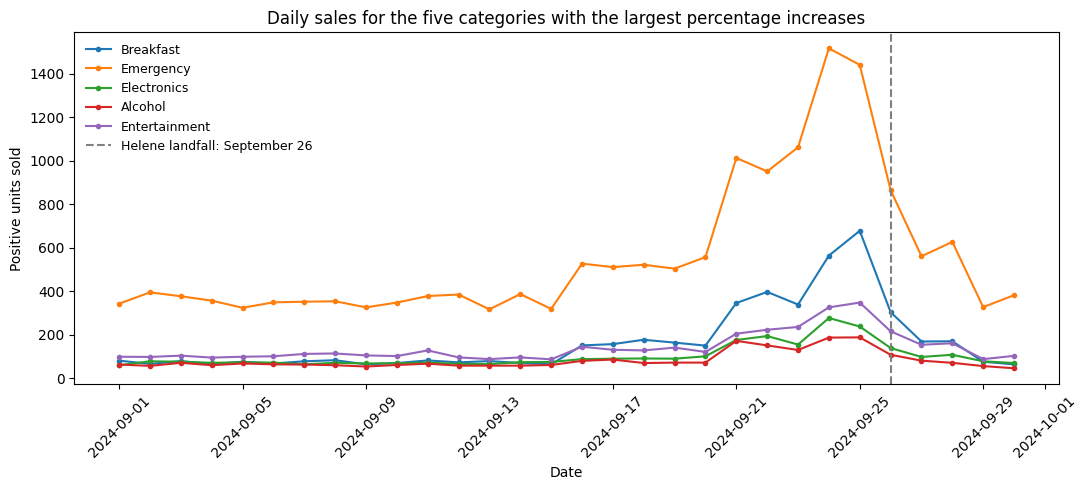

In [458]:
# Select the first five categories from the ranked comparison.
top_categories = category_comparison.head(5).index

# Create the chart.
fig, ax = plt.subplots(figsize=(11, 5))

for category in top_categories:
    category_sales = daily_category[
        daily_category["category"] == category
    ].sort_values("date")

    ax.plot(
        category_sales["date"],
        category_sales["quantity"],
        marker="o",
        ms=3,
        label=category
    )

# Mark hurricane landfall.
ax.axvline(
    LANDFALL,
    ls="--",
    color="gray",
    label="Helene landfall: September 26"
)

ax.set_title(
    "Daily sales for the five categories with the largest percentage increases"
)
ax.set_xlabel("Date")
ax.set_ylabel("Positive units sold")
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

##6.4 Findings and limitations

Breakfast had the largest percentage increase between our September 1 to 15 baseline and September 19 to 25 comparison window. Average daily sales rose from 73.27 to 376.86 units, or about 5.14 times baseline, a 414.36% increase. Emergency followed at 184.25%, then Electronics at 150.27%, Alcohol at 125.66%, and Entertainment at 124.97%.

Emergency had the highest average daily volume among the five categories plotted, at 1,006.43 units during the comparison window. Breakfast had the strongest relative growth. The daily chart shows purchasing increasing before September 26 landfall.

Our analysis includes 24,521 dated, positive-quantity sales records totaling 47,897 units. We removed exact duplicates and excluded 130 records with nonpositive quantities. Another 881 positive-sale records had no usable date and were excluded from daily analysis. These findings depend on the comparison windows we selected. Q3 examines the relationship between sales and weather.

###7. Q2 - Pop-tart consolidation

We will compare strawberry pop-tart sales across their original SKU identifiers with their combined canonical product total. This shows how fragmented identifiers can obscure daily demand

## 7.1 Identify the strawberry pop-tart SKU variants

Selects strawberry pop-tart records using their canonical SKU. It then reports sales under each original SKU and their combined total

In [459]:
# Select strawberry Pop-Tarts sales.
poptart_sales = analysis_sales[
    analysis_sales["canonical_sku"] == "POPTART-STRAW"
].copy()

# Total units recorded under each original SKU.
poptart_sku_units = (
    poptart_sales
    .groupby("original_sku")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Strawberry Pop-Tarts units by original SKU:")
display(poptart_sku_units)

print("Number of original SKUs:",
      poptart_sales["original_sku"].nunique())

print("Combined strawberry Pop-Tarts units:",
      poptart_sales["quantity"].sum())

Strawberry Pop-Tarts units by original SKU:


,quantity
original_sku,
PT-12,1332
POPTART-STRAW,1239
PT_STRAWBERRY,1230
SKU#459812,1204


Number of original SKUs: 4
Combined strawberry Pop-Tarts units: 5005


## 7.2 Calculate daily sales before and after SKU consolidation

This cell calculates daily sales separately for each original SKu and then combines them into one strawberry pop-tart total per day. The checks confirm that the consolidation preserves the recorded quantity

In [460]:
# Daily sales kept separate by original SKU.
poptart_daily_by_sku = (
    poptart_sales
    .groupby(["date", "original_sku"], as_index=False)["quantity"]
    .sum()
)

# Daily sales combined across all strawberry Pop-Tarts SKUs.
poptart_daily_combined = (
    poptart_sales
    .groupby("date", as_index=False)["quantity"]
    .sum()
)

print("Daily sales by original SKU — first eight rows:")
display(poptart_daily_by_sku.head(8))

print("Combined daily strawberry Pop-Tarts sales:")
display(poptart_daily_combined)

# Verify that both views preserve the original total.
units_before = poptart_sales["quantity"].sum()

print("Units preserved:", units_before)

Daily sales by original SKU — first eight rows:


,date,original_sku,quantity
0,2024-09-01,POPTART-STRAW,18
1,2024-09-01,PT-12,30
2,2024-09-01,PT_STRAWBERRY,13
3,2024-09-01,SKU#459812,20
4,2024-09-02,POPTART-STRAW,24
5,2024-09-02,PT-12,23
6,2024-09-02,PT_STRAWBERRY,9
7,2024-09-02,SKU#459812,10


Combined daily strawberry Pop-Tarts sales:


,date,quantity
0,2024-09-01,81
1,2024-09-02,66
2,2024-09-03,79
3,2024-09-04,66
4,2024-09-05,76
5,2024-09-06,68
6,2024-09-07,78
7,2024-09-08,83
8,2024-09-09,64
9,2024-09-10,70


Units preserved: 5005


## 7.1 and 7.2 Assertions

In [461]:
# Confirm that strawberry Pop-Tarts records are available.
assert len(poptart_sales) > 0, "No strawberry Pop-Tarts sales found"

assert (
    poptart_sales["original_sku"].notna().all()
), "Missing original SKU identifiers"

# The combined table must contain one record per date.
assert (
    poptart_daily_combined["date"].notna().all()
), "Missing dates in consolidated sales"

assert (
    poptart_daily_combined["date"].is_unique
), "Duplicate dates in consolidated sales"

# Both daily views must preserve the original quantity.
assert (
    poptart_daily_by_sku["quantity"].sum()
    == poptart_sales["quantity"].sum()
), "Separate-SKU totals changed"

assert (
    poptart_daily_combined["quantity"].sum()
    == poptart_sales["quantity"].sum()
), "Consolidation changed the unit total"

print("Q2 checks passed.")

Q2 checks passed.


## 7.3 Plot fragmented and consolidated daily sales

The left panel shows daily sales separately for each original SKU, while the right panel shows their combined daily volume. Both panels use the same vertical scale and represent the same recorded units

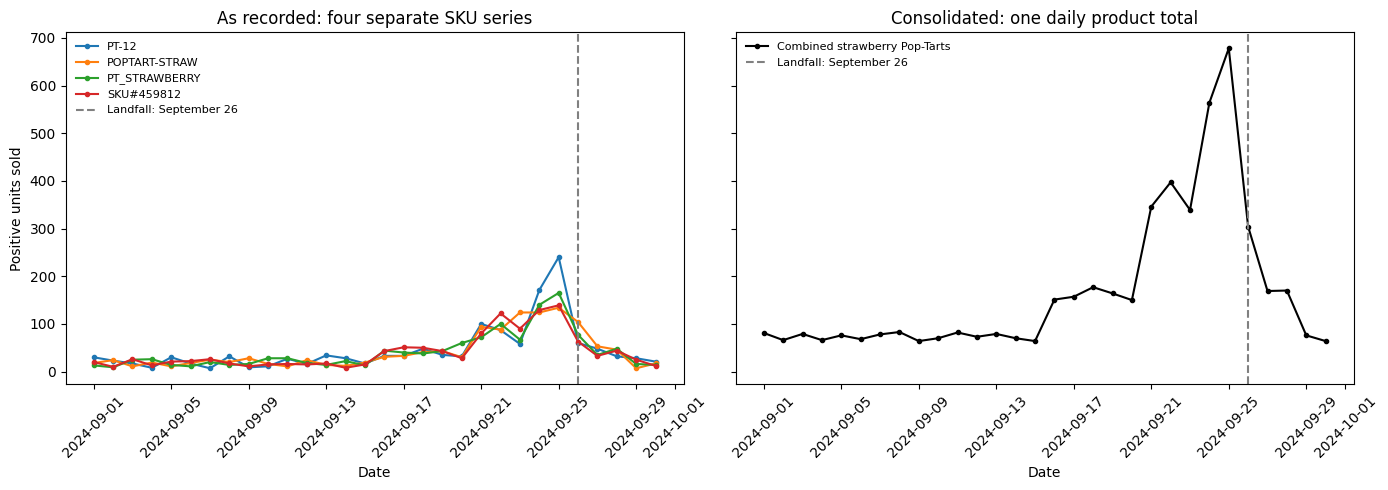

In [462]:
# Create side-by-side panels with the same vertical scale.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Left panel: separate daily series for each original SKU.
for sku in poptart_sku_units.index:
    sku_daily = poptart_daily_by_sku[
        poptart_daily_by_sku["original_sku"] == sku
    ].sort_values("date")

    axes[0].plot(
        sku_daily["date"],
        sku_daily["quantity"],
        marker="o",
        ms=3,
        label=sku
    )

axes[0].set_title("As recorded: four separate SKU series")
axes[0].set_ylabel("Positive units sold")

# Right panel: combined daily sales.
axes[1].plot(
    poptart_daily_combined["date"],
    poptart_daily_combined["quantity"],
    marker="o",
    ms=3,
    color="black",
    label="Combined strawberry Pop-Tarts"
)

axes[1].set_title("Consolidated: one daily product total")

# Apply the same labels and landfall marker to both panels.
for ax in axes:
    ax.axvline(
        LANDFALL,
        ls="--",
        color="gray",
        label="Landfall: September 26"
    )

    ax.set_xlabel("Date")
    ax.tick_params(axis="x", labelrotation=45)
    ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

## 7.4 Findings and business implications

Four SKU identifiers account for 5,005 recorded strawberry Pop-Tarts units across September. PT-12, the largest individual identifier, accounts for 1,332 units. The combined total is about 3.76 times that single-SKU total (5,005 ÷ 1,332). Grouping the identifiers gives us the full product-family volume while preserving the original quantity.

Combined daily sales peaked at 678 units on September 25, one day before landfall. A buyer reviewing separate identifiers could underestimate total demand for the family. Using the combined totals would help plan replenishment before the observed purchasing peak, with orders then allocated to the actual SKUs.

Package-size information in the catalog is inconsistent, so these totals describe recorded sales units. We need to verify package equivalence before converting them into individual Pop-Tarts or specific purchasing quantities.

##8. Q3 - Weather relationships and lag

We compare daily category sales with rainfall and wind at each store. We then check whether purchasing lines up more strongly with wind on the same day or several days later

## 8.1 Prepare daily category sales and weather

We total units for each store, date, and category. Each store's daily weather value repeats across its sales records, so taking the mean retains that measurement when we combine the records

In [463]:
# Create one row per store, date, and category.
daily_weather_sales = (
    analysis_weather
    .groupby(["store_id", "date", "category"], as_index=False)
    .agg(
        units=("quantity", "sum"),
        precipitation_sum=("precipitation_sum", "mean"),
        windspeed_10m_max=("windspeed_10m_max", "mean")
    )
)

print("Daily store/category records:", len(daily_weather_sales))
display(daily_weather_sales.head(10))

# Aggregating the records must preserve total sales units.
print("Units before aggregation:",
      analysis_weather["quantity"].sum())

print("Units after aggregation:",
      daily_weather_sales["units"].sum())



Daily store/category records: 3595


,store_id,date,category,units,precipitation_sum,windspeed_10m_max
0,FL-078,2024-09-01,Alcohol,3,1.5,11.3
1,FL-078,2024-09-01,Baby Products,9,1.5,11.3
2,FL-078,2024-09-01,Breakfast,4,1.5,11.3
3,FL-078,2024-09-01,Electronics,4,1.5,11.3
4,FL-078,2024-09-01,Emergency,27,1.5,11.3
5,FL-078,2024-09-01,Entertainment,12,1.5,11.3
6,FL-078,2024-09-01,Groceries,8,1.5,11.3
7,FL-078,2024-09-01,Health,4,1.5,11.3
8,FL-078,2024-09-01,Household,3,1.5,11.3
9,FL-078,2024-09-01,Snacks,3,1.5,11.3


Units before aggregation: 47897
Units after aggregation: 47897


## 8.1 Assertions

In [464]:
# Check the inputs before aggregation.
for column in [
    "store_id",
    "date",
    "category",
    "quantity",
    "precipitation_sum",
    "windspeed_10m_max"
]:
    assert analysis_weather[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    analysis_weather["quantity"] > 0
).all(), "Nonpositive quantities remain"

assert (
    daily_weather_sales["units"].sum()
    == analysis_weather["quantity"].sum()
), "Aggregation changed the unit total"

# Each variable must vary within a store/category group.
for column in ["units", "precipitation_sum", "windspeed_10m_max"]:
    assert (
        daily_weather_sales
        .groupby(["store_id", "category"])[column]
        .nunique() > 1
    ).all(), f"Some groups have no variation in {column}"

##8.2 Calculate same-day weather correlations

We calculate the correlation between daily category sales and each weather measurement within each store. The results include the number of paired days, with Orlando displayed for an initial review.

In [465]:
correlation_rows = []

# Calculate results separately for each store.
for store_id in daily_weather_sales["store_id"].unique():
    store_sales = daily_weather_sales[
        daily_weather_sales["store_id"] == store_id
    ]

    # Calculate results separately for each category.
    for category in store_sales["category"].unique():
        category_sales = store_sales[
            store_sales["category"] == category
        ]

        rain_r = category_sales["units"].corr(
            category_sales["precipitation_sum"]
        )

        wind_r = category_sales["units"].corr(
            category_sales["windspeed_10m_max"]
        )

        correlation_rows.append({
            "store_id": store_id,
            "category": category,
            "paired_days": len(category_sales),
            "rain_correlation": rain_r,
            "wind_correlation": wind_r
        })

category_correlations = pd.DataFrame(correlation_rows)

# Display Orlando while retaining all stores in the results table.
orlando_correlations = category_correlations[
    category_correlations["store_id"] == "FL-239"
]

display(orlando_correlations.round(3))

,store_id,category,paired_days,rain_correlation,wind_correlation
30,FL-239,Alcohol,30,-0.064,0.410
31,FL-239,Baby Products,30,-0.260,-0.124
32,FL-239,Breakfast,30,-0.232,0.457
33,FL-239,Electronics,30,-0.167,0.249
34,FL-239,Emergency,30,-0.242,0.506
35,FL-239,Entertainment,30,-0.177,0.414
36,FL-239,Groceries,30,-0.305,0.160
37,FL-239,Health,30,-0.207,0.365
38,FL-239,Household,30,-0.200,0.372
39,FL-239,Snacks,30,0.056,0.074


## 8.3 Plot same-day weather correlations

The panels compare Orlando category sales with rainfall and wind on the same day. A shared vertical scale makes sure the correlations are comparable

In [466]:
# Checks before plotting.
assert len(orlando_correlations) > 0, "No Orlando results found"

assert (
    orlando_correlations["category"].is_unique
), "Duplicate category results"

for column in ["rain_correlation", "wind_correlation"]:
    assert orlando_correlations[column].notna().all(), (
        f"Missing values in {column}"
    )

    assert (
        (orlando_correlations[column] >= -1)
        & (orlando_correlations[column] <= 1)
    ).all(), f"Invalid correlation values in {column}"

print("Correlation chart checks passed.")

Correlation chart checks passed.


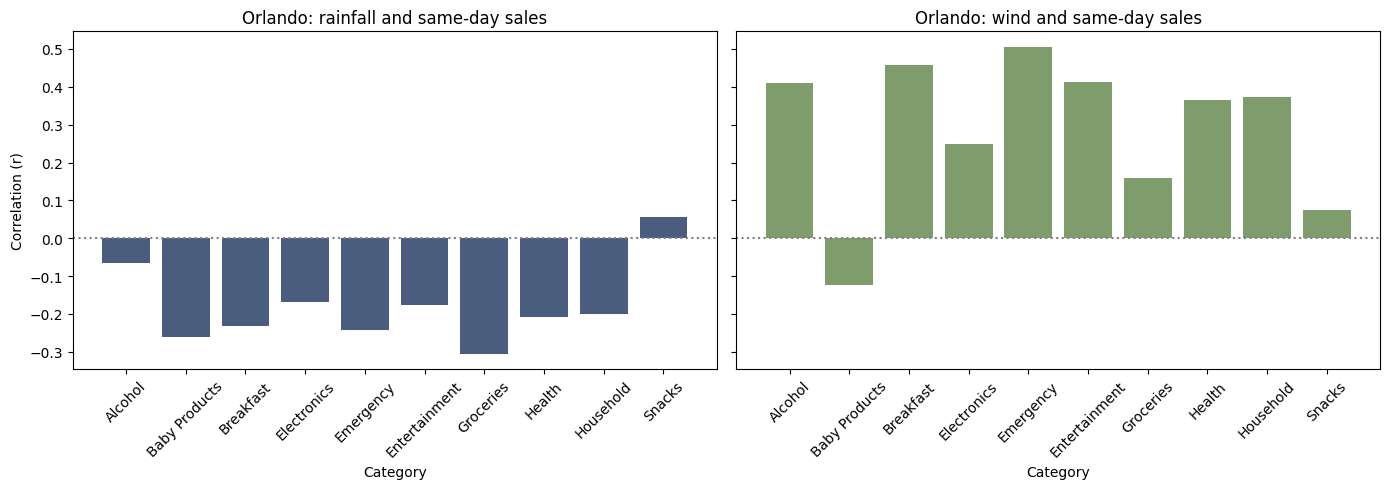

In [467]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Rainfall correlations.
axes[0].bar(
    orlando_correlations["category"],
    orlando_correlations["rain_correlation"],
    color="#4a5d7e"
)

axes[0].set_title("Orlando: rainfall and same-day sales")
axes[0].set_ylabel("Correlation (r)")

# Wind correlations.
axes[1].bar(
    orlando_correlations["category"],
    orlando_correlations["wind_correlation"],
    color="#7f9c6c"
)

axes[1].set_title("Orlando: wind and same-day sales")

for ax in axes:
    ax.axhline(0, color="gray", ls=":")
    ax.set_xlabel("Category")
    ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## 8.4 Compare sales with wind on later days

We compare Orlando's total daily sales across all categories with wind on the same day and up to four days later. Each result includes in paired-day count

In [468]:
# Select Orlando sales.
orlando_sales = analysis_weather[
    analysis_weather["store_id"] == "FL-239"
].copy()

# Create one record per day across all categories.
orlando_daily = (
    orlando_sales
    .groupby("date", as_index=False)
    .agg(
        units=("quantity", "sum"),
        windspeed_10m_max=("windspeed_10m_max", "mean")
    )
    .sort_values("date")
)

In [469]:
# Check required values.
for column in ["date", "units", "windspeed_10m_max"]:
    assert orlando_daily[column].notna().all(), (
        f"Missing values in {column}"
    )

assert orlando_daily["date"].is_unique, "Duplicate sales dates"

assert (
    orlando_daily["units"].sum()
    == orlando_sales["quantity"].sum()
), "Daily aggregation changed Orlando units"

# A row shift must represent exactly one calendar day.
expected_dates = pd.date_range(START, END)

assert (
    len(orlando_daily) == len(expected_dates)
), "Missing daily records"

assert (
    orlando_daily["date"] == expected_dates
).all(), "Dates are incomplete or out of order"

# Correlation requires variation.
assert orlando_daily["units"].nunique() > 1, "Sales do not vary"
assert (
    orlando_daily["windspeed_10m_max"].nunique() > 1
), "Wind speed does not vary"

print("Lag analysis checks passed.")

Lag analysis checks passed.


In [470]:
lag_rows = []

for k in range(0, 5):
    pairs = pd.DataFrame({
        "units_today": orlando_daily["units"],
        "wind_later": orlando_daily["windspeed_10m_max"].shift(-k)
    }).dropna()

    lag_rows.append({
        "wind_days_later": k,
        "paired_days": len(pairs),
        "correlation": pairs["units_today"].corr(pairs["wind_later"])
    })

lag_results = pd.DataFrame(lag_rows)

display(lag_results.round(3))

,wind_days_later,paired_days,correlation
0,0,30,0.458
1,1,29,0.688
2,2,28,0.773
3,3,27,0.669
4,4,26,0.545


## 8.5 Plot the lag comparison

The chart compares sales with wind measured zero to four days later. The horizontal axis states the direction of the comparison so the lag is clear

In [471]:
# Confirm the five intended lags are present.
assert (
    lag_results["wind_days_later"].tolist() == [0, 1, 2, 3, 4]
), "Unexpected lag values"

assert (
    lag_results["correlation"].notna().all()
), "Missing lag correlations"

assert (
    (lag_results["correlation"] >= -1)
    & (lag_results["correlation"] <= 1)
).all(), "Invalid correlation values"

# Each additional lag removes one available paired day.
assert (
    lag_results["paired_days"]
    == len(orlando_daily) - lag_results["wind_days_later"]
).all(), "Unexpected paired-day counts"

print("Lag chart checks passed.")

Lag chart checks passed.


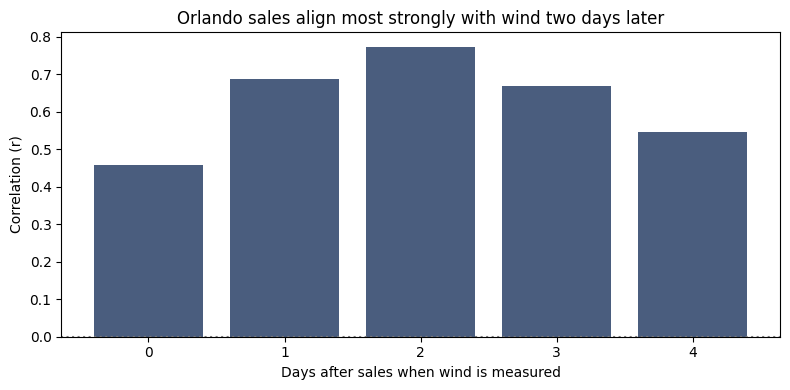

In [472]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    lag_results["wind_days_later"].astype(str),
    lag_results["correlation"],
    color="#4a5d7e"
)

ax.set_title(
    "Orlando sales align most strongly with wind two days later"
)
ax.set_xlabel("Days after sales when wind is measured")
ax.set_ylabel("Correlation (r)")
ax.axhline(0, color="gray", ls=":")

plt.tight_layout()
plt.show()

## 8.6 Findings and limitations

We calculated weather correlations separately for each store and category. The charts and discussion here focus on Orlando, where each category had 30 paired days.

Emergency had the highest same-day wind correlation at 0.506, followed by Breakfast at 0.457. Baby Products had a negative wind correlation of −0.124. Rainfall correlations were mostly negative, with Groceries having the most negative value at −0.305. These differences show that the same-day relationship with weather varied across categories.

For Orlando’s total sales across all categories, the same-day wind correlation was 0.458 across 30 days. Comparing sales with wind two days later produced the highest correlation among the five tested lags: 0.773 across 28 paired days. This pattern is consistent with purchasing ahead of stronger winds.

The analysis covers one store during September 2024. We tested lags from zero to four days and selected the highest correlation, so the result should be treated as exploratory. It does not establish that weather caused the purchasing changes.

Orlando’s weather was requested from the Open-Meteo archive API using America/New_York. We matched sales calendar dates to those local weather dates, but the timezone convention of the original sales timestamps still needs confirmation.

## 9. Q4 - Store level geographic patterns

We compare the size and timing of sales changes across stores, then examine their locations and regions. Any conclusions about proximity to the hurricane path will need supporting geographic evidence

## 9.1 Prepare daily store sales and locations information

We total positive units and count sales records for each store and date. A separate lookup connects standardized store identifiers with their cities and regions

In [473]:
# One record per store and date.
store_daily = (
    analysis_weather
    .groupby(["store_id", "date"], as_index=False)
    .agg(
        units=("quantity", "sum"),
        sales_records=("quantity", "count")
    )
)

# Keep the location fields needed for this comparison.
store_lookup = store[["store_id", "city", "region"]].copy()
store_lookup["region"] = store_lookup["region"].str.strip()

# Apply the same store-ID formatting used earlier.
store_lookup["store_id"] = (
    store_lookup["store_id"]
    .str.upper()
    .str.strip()
    .str.replace(r"[^A-Z0-9]", "", regex=True)
    .apply(lambda s: f"{s[:2]}-{s[2:]}")
)

# Remove identical lookup records.
store_lookup = store_lookup.drop_duplicates()

In [474]:
# Check the location lookup.
for column in ["store_id", "city", "region"]:
    assert store_lookup[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    store_lookup["store_id"].is_unique
), "Conflicting or duplicate store lookup keys"

# Confirm aggregation preserved units and sales records.
assert (
    store_daily["units"].sum()
    == analysis_weather["quantity"].sum()
), "Store aggregation changed total units"

assert (
    store_daily["sales_records"].sum()
    == len(analysis_weather)
), "Store aggregation changed the sales-record count"

# Every sales store must have location information.
for store_id in store_daily["store_id"].unique():
    assert store_id in store_lookup["store_id"].tolist(), (
        f"No location information for {store_id}"
    )

# Each store should cover the full analysis calendar.
expected_days = len(pd.date_range(START, END))

assert (
    store_daily.groupby("store_id")["date"].count()
    == expected_days
).all(), "Some stores have incomplete daily coverage"

print("Store preparation checks passed.")

Store preparation checks passed.


In [475]:
store_daily_locations = store_daily.merge(
    store_lookup,
    on="store_id",
    how="left",
    indicator=True
)

print("Stores:", store_daily_locations["store_id"].nunique())
print("Daily store records:", len(store_daily_locations))
print("Total units:", store_daily_locations["units"].sum())

print("Location match counts:")
print(store_daily_locations["_merge"].value_counts())

display(store_daily_locations.head(10))

Stores: 12
Daily store records: 360
Total units: 47897
Location match counts:
_merge
both          360
left_only       0
right_only      0
Name: count, dtype: int64


,store_id,date,units,sales_records,city,region,_merge
0,FL-078,2024-09-01,77,42,Gainesville,North,both
1,FL-078,2024-09-02,103,49,Gainesville,North,both
2,FL-078,2024-09-03,101,47,Gainesville,North,both
3,FL-078,2024-09-04,84,46,Gainesville,North,both
4,FL-078,2024-09-05,90,43,Gainesville,North,both
5,FL-078,2024-09-06,96,45,Gainesville,North,both
6,FL-078,2024-09-07,90,51,Gainesville,North,both
7,FL-078,2024-09-08,98,54,Gainesville,North,both
8,FL-078,2024-09-09,84,48,Gainesville,North,both
9,FL-078,2024-09-10,86,46,Gainesville,North,both


## 9.2 Calculate store-level store changes

We compare each store's average daily units during September 19 to 25 with its September 1 to 15 baseline. The results include city and region so we can examine geographic differences

In [476]:
store_baseline_days = store_daily_locations[
    (store_daily_locations["date"] >= "2024-09-01")
    & (store_daily_locations["date"] <= "2024-09-15")
]

store_surge_days = store_daily_locations[
    (store_daily_locations["date"] >= "2024-09-19")
    & (store_daily_locations["date"] <= "2024-09-25")
]

In [477]:
# Confirm the location join preserved sales.
assert (
    len(store_daily_locations) == len(store_daily)
), "Location join changed the row count"

assert (
    store_daily_locations["units"].sum()
    == store_daily["units"].sum()
), "Location join changed total units"

assert (
    store_daily_locations["_merge"] == "both"
).all(), "Some stores have no matching location"

assert (
    store_daily_locations["units"] > 0
).all(), "Nonpositive daily store totals"

# Confirm every store appears in both windows.
assert (
    store_baseline_days["store_id"].nunique()
    == store_lookup["store_id"].nunique()
), "Some stores are missing from the baseline"

assert (
    store_surge_days["store_id"].nunique()
    == store_lookup["store_id"].nunique()
), "Some stores are missing from the comparison window"

# Check complete windows for every store.
assert (
    store_baseline_days.groupby("store_id")["date"].count() == 15
).all(), "Incomplete store baseline"

assert (
    store_surge_days.groupby("store_id")["date"].count() == 7
).all(), "Incomplete store comparison window"

print("Store comparison checks passed.")

Store comparison checks passed.


In [478]:
# Average daily units during the baseline.
baseline_store_average = (
    store_baseline_days
    .groupby("store_id", as_index=False)["units"]
    .mean()
    .rename(columns={"units": "baseline_units_per_day"})
)

# Average daily units during the comparison window.
comparison_store_average = (
    store_surge_days
    .groupby("store_id", as_index=False)["units"]
    .mean()
    .rename(columns={"units": "comparison_units_per_day"})
)

# Combine the averages and location information.
store_surge_summary = baseline_store_average.merge(
    comparison_store_average,
    on="store_id",
    how="left"
)

store_surge_summary = store_surge_summary.merge(
    store_lookup,
    on="store_id",
    how="left"
)

# Calculate relative changes.
store_surge_summary["multiple"] = (
    store_surge_summary["comparison_units_per_day"]
    / store_surge_summary["baseline_units_per_day"]
)

store_surge_summary["percent_change"] = (
    (store_surge_summary["multiple"] - 1) * 100
)

store_surge_summary = store_surge_summary.sort_values(
    "percent_change",
    ascending=False
)

display(store_surge_summary.round(2))

,store_id,baseline_units_per_day,comparison_units_per_day,city,region,multiple,percent_change
6,FL-330,86.73,235.43,Miami,South,2.71,171.44
10,FL-619,86.13,224.14,Tallahassee,Panhandle,2.60,160.23
1,FL-105,91.73,231.71,Tampa,West,2.53,152.60
7,FL-412,89.47,222.86,Jacksonville,North,2.49,149.10
5,FL-302,96.27,239.43,Lakeland,Central,2.49,148.71
8,FL-445,94.53,232.00,St. Petersburg,West,2.45,145.42
11,FL-710,93.40,227.86,Pensacola,Panhandle,2.44,143.96
4,FL-287,91.07,220.14,Kissimmee,Central,2.42,141.74
2,FL-156,94.93,229.14,Daytona Beach,East,2.41,141.37
9,FL-501,92.53,220.57,Fort Myers,West,2.38,138.37


### 9.3 Plot store-level sales changes

The chart ranks stores by their percentage change in average daily units. City labels identify the stores, using the same baseline and comparison windows throughout

In [479]:
# Confirm that every store has one summary record.
assert (
    len(store_surge_summary) == len(store_lookup)
), "Some stores are missing from the summary"

assert (
    store_surge_summary["store_id"].is_unique
), "Duplicate store summary records"

# Check the values needed for the chart.
for column in [
    "store_id",
    "city",
    "baseline_units_per_day",
    "comparison_units_per_day",
    "percent_change"
]:
    assert store_surge_summary[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    store_surge_summary["baseline_units_per_day"] > 0
).all(), "Baseline averages must be positive"

# City labels must distinguish the stores in this chart.
assert (
    store_surge_summary["city"].is_unique
), "Use store IDs to distinguish stores sharing a city"

print("Store chart checks passed.")

Store chart checks passed.


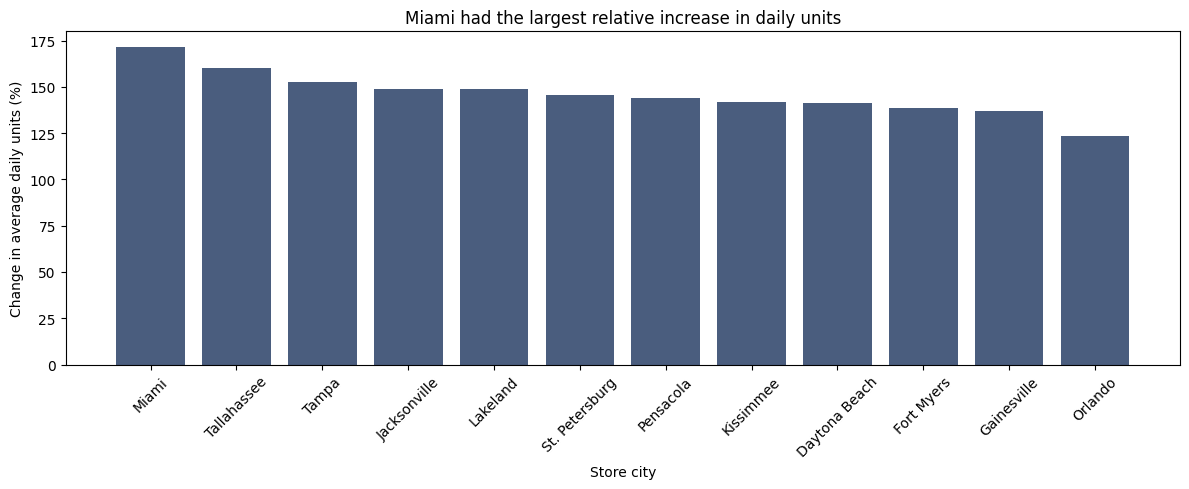

In [480]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    store_surge_summary["city"],
    store_surge_summary["percent_change"],
    color="#4a5d7e"
)

ax.set_title(
    "Miami had the largest relative increase in daily units"
)
ax.set_xlabel("Store city")
ax.set_ylabel("Change in average daily units (%)")
ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## 9.4 Identify each store's peak sales date

We identify each store's highest daily positive unit toal during September. If a store reaches the same maximum on multiple dates, we retain every tied date

In [481]:
# Check the fields needed to identify and describe peaks.
for column in ["store_id", "date", "units", "city", "region"]:
    assert store_daily_locations[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    store_daily_locations["units"] > 0
).all(), "Nonpositive daily store totals"

assert store_daily_locations.duplicated(
    subset=["store_id", "date"]
).sum() == 0, "Duplicate store/date records"

assert (
    store_daily_locations["units"].sum()
    == analysis_weather["quantity"].sum()
), "Store totals no longer match the prepared sales"

print("Store peak-date checks passed.")

Store peak-date checks passed.


In [482]:
peak_tables = []

for store_id in store_daily_locations["store_id"].unique():
    store_days = store_daily_locations[
        store_daily_locations["store_id"] == store_id
    ]

    # Find the highest daily quantity for this store.
    peak_units = store_days["units"].max()

    # Keep every date that reached that maximum.
    peak_days = store_days[
        store_days["units"] == peak_units
    ]

    peak_tables.append(
        peak_days[["store_id", "city", "region", "date", "units"]]
    )

# Combine the peak records into one table.
store_peak_summary = pd.concat(
    peak_tables,
    ignore_index=True
)

store_peak_summary = store_peak_summary.rename(
    columns={
        "date": "peak_date",
        "units": "peak_units"
    }
)

store_peak_summary = store_peak_summary.sort_values(
    ["peak_date", "city"]
)

print("Landfall: September 26, 2024")
display(store_peak_summary)

Landfall: September 26, 2024


,store_id,city,region,peak_date,peak_units
2,FL-156,Daytona Beach,East,2024-09-24,329
9,FL-501,Fort Myers,West,2024-09-24,310
6,FL-330,Miami,South,2024-09-24,326
3,FL-239,Orlando,Central,2024-09-24,291
8,FL-445,St. Petersburg,West,2024-09-24,352
11,FL-619,Tallahassee,Panhandle,2024-09-24,317
10,FL-501,Fort Myers,West,2024-09-25,310
0,FL-078,Gainesville,North,2024-09-25,324
7,FL-412,Jacksonville,North,2024-09-25,340
4,FL-287,Kissimmee,Central,2024-09-25,312


### 9.5 Compare sales changes across regions

We add each region's store averages and calcuilate its percentage changes. The store count helps us distinguish regions represented by several stores from those represented by one

In [483]:
region_summary = (
    store_surge_summary
    .groupby("region", as_index=False)
    .agg(
        stores=("store_id", "count"),
        baseline_units_per_day=("baseline_units_per_day", "sum"),
        comparison_units_per_day=("comparison_units_per_day", "sum")
    )
)

In [484]:
# Each store must contribute only once.
assert (
    store_surge_summary["store_id"].is_unique
), "Duplicate stores would distort the regional totals"

assert (
    store_surge_summary["region"].notna().all()
), "Some stores have no region"

assert (
    region_summary["stores"].sum() == len(store_lookup)
), "Regional totals do not include every store exactly once"

for column in [
    "region",
    "baseline_units_per_day",
    "comparison_units_per_day"
]:
    assert region_summary[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    store_surge_summary["region"]
    == store_surge_summary["region"].str.strip()
).all(), "Region labels contain extra spaces"


assert (
    region_summary["baseline_units_per_day"] > 0
).all(), "Regional baseline totals must be positive"

print("Regional comparison checks passed.")

Regional comparison checks passed.


In [485]:
region_summary["multiple"] = (
    region_summary["comparison_units_per_day"]
    / region_summary["baseline_units_per_day"]
)

region_summary["percent_change"] = (
    (region_summary["multiple"] - 1) * 100
)

region_summary = region_summary.sort_values(
    "percent_change",
    ascending=False
)

display(region_summary.round(2))

,region,stores,baseline_units_per_day,comparison_units_per_day,multiple,percent_change
4,South,1,86.73,235.43,2.71,171.44
3,Panhandle,2,179.53,452.00,2.52,151.76
5,West,3,278.80,684.29,2.45,145.44
2,North,2,181.87,441.86,2.43,142.96
1,East,1,94.93,229.14,2.41,141.37
0,Central,3,281.13,669.14,2.38,138.02


### 9.6 Findings and limitations

All twelve stores had higher average daily positive-unit sales during September 19 to 25 than during the September 1 to 15 baseline. Miami had the largest percentage increase at 171.44%, and Orlando had the smallest at 123.42%. These stores are candidates for further investigation because they sit at opposite ends of the ranking. We have not applied a formal statistical outlier test.

Lakeland had the highest comparison-period average at 239.43 units per day and the largest single-day total at 403 units on September 25. All stores reached their September peaks on September 24 or 25, one or two days before landfall. Fort Myers tied at 310 units on both dates, so both peak records were retained.

The South region had the largest percentage increase at 171.44%, but it contains only the Miami store. Panhandle increased by 151.76% across two stores, while Central increased by 138.02% across three stores. The different store counts limit how broadly we can interpret these regional comparisons.

Our location data identifies cities and regions but does not include distances to the predicted hurricane path. We can describe differences in sales magnitude and timing, but these results do not establish whether stores closer to that path had earlier or larger spikes.

### 10. Q5 - The board-game investigation

### 10.1 Inspect database categories and entertainment products

We summarize the database's reported sales by category and list the original SKUs classified as entertainment in our cleaned sales. We also inspect missing inventory values before deciding how they should be handled

In [486]:
# Confirm the database tables are available.
assert len(daily_sales_clean) > 0, "Database sales table is empty"

assert len(inventory_levels_clean) > 0, "Inventory table is empty"

# Confirm the required columns exist.
for column in ["date", "store_id", "category", "total_units"]:
    assert column in daily_sales_clean.columns, (
        f"Missing sales column: {column}"
    )

for column in [
    "date",
    "store_id",
    "sku",
    "canonical_sku",
    "units_on_hand",
    "units_on_order",
    "reorder_point"
]:
    assert column in inventory_levels_clean.columns, (
        f"Missing inventory column: {column}"
    )

print("Q5 input checks passed.")

Q5 input checks passed.


In [487]:
# Query the original SQLite sales table.
conn = sqlite3.connect(db_filepath)

sql_category_summary = pd.read_sql_query("""
    SELECT
        category,
        COUNT(*) AS records,
        SUM(total_units) AS reported_units
    FROM daily_sales_summary
    GROUP BY category
    ORDER BY reported_units DESC
""", conn)

conn.close()

print("Full-month category totals reported by SQLite:")
display(sql_category_summary)

# Identify the products included in Entertainment sales.
entertainment_products = analysis_sales[
    analysis_sales["category"] == "Entertainment"
][
    ["original_sku", "canonical_sku", "product_name", "category"]
].drop_duplicates().sort_values("canonical_sku")

print("Products classified as Entertainment in the CSV:")
display(entertainment_products)

print("Missing inventory values:")
display(inventory_levels_clean.isna().sum())

Full-month category totals reported by SQLite:


,category,records,reported_units
0,Breakfast,360,30700.0
1,Emergency,360,26332.5
2,Alcohol,360,24246.5
3,Entertainment,360,24070.0
4,Electronics,360,23792.5
5,Health,360,23670.5
6,Household,360,22809.0
7,Baby,360,20961.5
8,Grocery,360,20568.0
9,Snacks,360,19988.5


Products classified as Entertainment in the CSV:


,original_sku,canonical_sku,product_name,category
65,BG-MONO,GAME-MONO,Monopoly Board Game,Entertainment
76,MONOPOLY-01,GAME-MONO,Monopoly Board Game,Entertainment
157,GAME-MONO,GAME-MONO,Monopoly Board Game,Entertainment
292,MONOPOLY-01,GAME-MONO,Monopoly,Entertainment
385,BG-MONO,GAME-MONO,Monopoly,Entertainment
612,GAME-MONO,GAME-MONO,Monopoly,Entertainment
10,CARDS-01,PLAYCARD,Playing Cards,Entertainment
42,CARDS-01,PLAYCARD,Standard Playing Cards,Entertainment
61,PLAYCARD-STD,PLAYCARD,Playing Cards,Entertainment
426,PLAYCARD-STD,PLAYCARD,Standard Playing Cards,Entertainment


Missing inventory values:


,0
date,0
store_id,0
sku,0
units_on_hand,0
units_on_order,626
reorder_point,0
canonical_sku,0


### 10.2 Prepare daily database and transaction comparisons

We prepare daily entertainment totals from SQLite and the transaction CSV. Separate board game and playing card series let us examine what contributes to the broader category

In [488]:
# Work from a copy of the cleaned database sales.
q5_db_sales = daily_sales_clean.copy()

q5_db_sales["date"] = pd.to_datetime(
    q5_db_sales["date"],
    format="mixed",
    errors="coerce"
).dt.normalize()

q5_db_sales["category"] = (
    q5_db_sales["category"].str.strip().str.title()
)

q5_db_sales["total_units"] = pd.to_numeric(
    q5_db_sales["total_units"],
    errors="coerce"
)

# Select the category and product families.
db_entertainment = q5_db_sales[
    q5_db_sales["category"] == "Entertainment"
]

csv_entertainment = analysis_sales[
    analysis_sales["category"] == "Entertainment"
]

csv_board_games = analysis_sales[
    analysis_sales["canonical_sku"] == "GAME-MONO"
]

csv_playing_cards = analysis_sales[
    analysis_sales["canonical_sku"] == "PLAYCARD"
]

# Align the daily totals by date.
q5_daily = pd.DataFrame({
    "sqlite_entertainment":
        db_entertainment.groupby("date")["total_units"].sum(),

    "csv_entertainment":
        csv_entertainment.groupby("date")["quantity"].sum(),

    "csv_board_games":
        csv_board_games.groupby("date")["quantity"].sum(),

    "csv_playing_cards":
        csv_playing_cards.groupby("date")["quantity"].sum()
})

In [489]:
# Check the database fields used in the comparison.
for column in ["date", "category", "total_units"]:
    assert q5_db_sales[column].notna().all(), (
        f"Missing database values in {column}"
    )

# Check complete, aligned daily coverage.
expected_dates = pd.date_range(START, END)

assert len(q5_daily) == len(expected_dates), "Incomplete daily coverage"

assert (
    q5_daily.index == expected_dates
).all(), "Dates do not match the analysis calendar"

for column in q5_daily.columns:
    assert q5_daily[column].notna().all(), (
        f"Missing daily values in {column}"
    )

# Check whether the two product families account for Entertainment.
assert (
    q5_daily["csv_board_games"]
    + q5_daily["csv_playing_cards"]
    == q5_daily["csv_entertainment"]
).all(), "Entertainment includes other products or category mismatches"

print("Q5 daily comparison checks passed.")

Q5 daily comparison checks passed.


In [490]:
print("Daily comparison — first ten days:")
display(q5_daily.head(10))

print("Full-month totals:")
display(q5_daily.sum())

Daily comparison — first ten days:


,sqlite_entertainment,csv_entertainment,csv_board_games,csv_playing_cards
date,,,,
2024-09-01,544.0,99,45,54
2024-09-02,498.0,98,46,52
2024-09-03,504.0,104,38,66
2024-09-04,600.5,95,38,57
2024-09-05,551.0,99,36,63
2024-09-06,464.0,101,43,58
2024-09-07,624.0,112,54,58
2024-09-08,622.0,114,51,63
2024-09-09,613.0,105,42,63


Full-month totals:


,0
sqlite_entertainment,24070.0
csv_entertainment,4250.0
csv_board_games,1938.0
csv_playing_cards,2312.0


### 10.3 Compare percentage changes using the same windows

We compare September 19 to 25 with the September 1 to 15 baseline for each series. This separates the database result, the CSV's broader entertainment category, and the two product families

In [491]:
# Dates are the index of q5_daily.
q5_baseline = q5_daily[
    (q5_daily.index >= "2024-09-01")
    & (q5_daily.index <= "2024-09-15")
]

q5_surge = q5_daily[
    (q5_daily.index >= "2024-09-19")
    & (q5_daily.index <= "2024-09-25")
]

In [492]:
assert len(q5_baseline) == 15, "Incomplete baseline window"
assert len(q5_surge) == 7, "Incomplete comparison window"

for column in q5_daily.columns:
    assert q5_baseline[column].notna().all(), (
        f"Missing baseline values in {column}"
    )

    assert q5_surge[column].notna().all(), (
        f"Missing comparison values in {column}"
    )

    assert q5_baseline[column].sum() > 0, (
        f"Baseline must be positive for {column}"
    )

print("Q5 comparison-window checks passed.")

Q5 comparison-window checks passed.


In [493]:
q5_growth = pd.DataFrame({
    "baseline_units_per_day": q5_baseline.mean(),
    "comparison_units_per_day": q5_surge.mean()
})

q5_growth["multiple"] = (
    q5_growth["comparison_units_per_day"]
    / q5_growth["baseline_units_per_day"]
)

q5_growth["percent_change"] = (
    (q5_growth["multiple"] - 1) * 100
)

display(q5_growth.round(2))

,baseline_units_per_day,comparison_units_per_day,multiple,percent_change
sqlite_entertainment,568.47,1394.50,2.45,145.31
csv_entertainment,101.60,228.57,2.25,124.97
csv_board_games,42.87,111.43,2.60,159.94
csv_playing_cards,58.73,117.14,1.99,99.45


### 10.4 Plot the reported growth comparisons

The chart compares all four percentage changes under the same date windows. A reference line marks the reported 250% increase

In [494]:
# Confirm the row order matches the chart labels.
expected_series = [
    "sqlite_entertainment",
    "csv_entertainment",
    "csv_board_games",
    "csv_playing_cards"
]

assert (
    q5_growth.index.tolist() == expected_series
), "Unexpected series or ordering"

assert (
    q5_growth["percent_change"].notna().all()
), "Missing percentage changes"

assert (
    q5_growth["baseline_units_per_day"] > 0
).all(), "Baseline averages must be positive"

print("Q5 chart checks passed.")

Q5 chart checks passed.


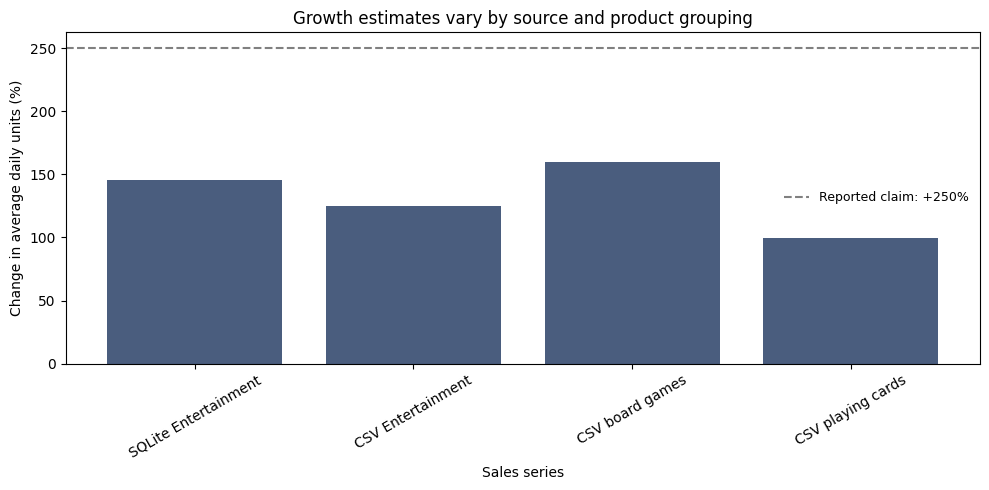

In [495]:
labels = [
    "SQLite Entertainment",
    "CSV Entertainment",
    "CSV board games",
    "CSV playing cards"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    labels,
    q5_growth["percent_change"],
    color="#4a5d7e"
)

ax.axhline(
    250,
    color="gray",
    ls="--",
    label="Reported claim: +250%"
)

ax.set_title(
    "Growth estimates vary by source and product grouping"
)
ax.set_xlabel("Sales series")
ax.set_ylabel("Change in average daily units (%)")
ax.tick_params(axis="x", labelrotation=30)
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

### 10.5 Inspect board game inventory records

We inspect inventory records mapped to the board game family. The results show available dates, missing order quantities, and overlapping SKU records without adding their stock quantities together

In [496]:
board_inventory = inventory_levels_clean[
    inventory_levels_clean["canonical_sku"] == "GAME-MONO"
].copy()

board_inventory["store_id"] = (
    board_inventory["store_id"]
    .str.upper()
    .str.strip()
    .str.replace(r"[^A-Z0-9]", "", regex=True)
    .apply(lambda s: f"{s[:2]}-{s[2:]}")
)

board_inventory["date"] = pd.to_datetime(
    board_inventory["date"],
    format="mixed",
    errors="coerce"
).dt.normalize()

for column in ["units_on_hand", "units_on_order", "reorder_point"]:
    board_inventory[column] = pd.to_numeric(
        board_inventory[column],
        errors="coerce"
    )

# Create flags for counting inventory conditions.
board_inventory["missing_order_quantity"] = (
    board_inventory["units_on_order"].isna()
)

board_inventory["zero_on_hand"] = (
    board_inventory["units_on_hand"] == 0
)

board_inventory["below_reorder_point"] = (
    board_inventory["units_on_hand"]
    < board_inventory["reorder_point"]
)

In [497]:
assert len(board_inventory) > 0, "No board-game inventory found"

for column in [
    "store_id",
    "date",
    "sku",
    "units_on_hand",
    "reorder_point"
]:
    assert board_inventory[column].notna().all(), (
        f"Missing values in {column}"
    )

assert (
    (board_inventory["date"] >= START)
    & (board_inventory["date"] <= END)
).all(), "Inventory dates fall outside the analysis period"

for store_id in board_inventory["store_id"].unique():
    assert store_id in store_lookup["store_id"].tolist(), (
        f"Unknown inventory store: {store_id}"
    )

print("Board-game inventory checks passed.")

Board-game inventory checks passed.


In [498]:
# Summarize the available records for each store.
inventory_coverage = (
    board_inventory
    .groupby("store_id", as_index=False)
    .agg(
        inventory_records=("sku", "count"),
        observed_days=("date", "nunique"),
        missing_order_quantities=("missing_order_quantity", "sum")
    )
)

display(inventory_coverage)

# Count records and distinct SKU variants on each store/date.
inventory_by_day = (
    board_inventory
    .groupby(["store_id", "date"], as_index=False)
    .agg(
        inventory_records=("sku", "count"),
        raw_skus=("sku", "nunique")
    )
)

overlapping_inventory_days = inventory_by_day[
    inventory_by_day["raw_skus"] > 1
]

expected_store_days = (
    len(store_lookup) * len(pd.date_range(START, END))
)

print("Board-game inventory records:", len(board_inventory))
print("Store-days with an inventory record:", len(inventory_by_day))
print("Possible store-days:", expected_store_days)

print("Store-days without a board-game inventory record:",
      expected_store_days - len(inventory_by_day))

print("Records missing order quantities:",
      board_inventory["missing_order_quantity"].sum())

print("Records with zero units on hand:",
      board_inventory["zero_on_hand"].sum())

print("Records below the reorder point:",
      board_inventory["below_reorder_point"].sum())

print("Store-days containing multiple SKU variants:",
      len(overlapping_inventory_days))

display(overlapping_inventory_days.head(10))

,store_id,inventory_records,observed_days,missing_order_quantities
0,FL-078,16,14,3
1,FL-105,23,15,4
2,FL-156,24,20,6
3,FL-239,20,16,3
4,FL-287,28,21,5
5,FL-302,23,18,2
6,FL-330,23,17,3
7,FL-412,29,22,4
8,FL-445,29,21,5
9,FL-501,20,17,3


Board-game inventory records: 277
Store-days with an inventory record: 218
Possible store-days: 360
Store-days without a board-game inventory record: 142
Records missing order quantities: 45
Records with zero units on hand: 0
Records below the reorder point: 54
Store-days containing multiple SKU variants: 54


,store_id,date,inventory_records,raw_skus
6,FL-078,2024-09-15,2,2
12,FL-078,2024-09-29,2,2
14,FL-105,2024-09-01,2,2
17,FL-105,2024-09-06,3,3
18,FL-105,2024-09-11,2,2
20,FL-105,2024-09-14,3,3
26,FL-105,2024-09-26,2,2
27,FL-105,2024-09-29,2,2
29,FL-156,2024-09-01,2,2
33,FL-156,2024-09-07,2,2


### 10.6 Reconcile entertainment sales by store and date

We match the two sources by store and date to distinguish missing matches from differences in reported units

In [499]:
q5_database_rows = db_entertainment[
    ["store_id", "date", "total_units"]
].copy().rename(columns={"total_units": "database_units"})

q5_csv_rows = csv_entertainment[
    ["store_id", "date", "quantity"]
].copy()

# Standardize store IDs before grouping or matching.
for table in [q5_database_rows, q5_csv_rows]:
    table["store_id"] = (
        table["store_id"]
        .str.upper()
        .str.strip()
        .str.replace(r"[^A-Z0-9]", "", regex=True)
        .apply(lambda s: f"{s[:2]}-{s[2:]}")
    )

q5_csv_daily = (
    q5_csv_rows
    .groupby(["store_id", "date"], as_index=False)["quantity"]
    .sum()
    .rename(columns={"quantity": "csv_units"})
)

In [500]:
for column in ["store_id", "date"]:
    assert q5_database_rows[column].notna().all(), (
        f"Missing database {column}"
    )

    assert q5_csv_daily[column].notna().all(), (
        f"Missing CSV {column}"
    )

assert q5_database_rows["database_units"].notna().all()
assert q5_csv_daily["csv_units"].notna().all()

assert q5_database_rows.duplicated(
    subset=["store_id", "date"]
).sum() == 0, "Duplicate database store/date summaries"

assert q5_csv_daily.duplicated(
    subset=["store_id", "date"]
).sum() == 0, "Duplicate CSV store/date summaries"

print("Cross-source matching checks passed.")

Cross-source matching checks passed.


In [501]:
q5_reconciliation = q5_database_rows.merge(
    q5_csv_daily,
    on=["store_id", "date"],
    how="outer",
    indicator=True
)

q5_reconciliation["difference"] = (
    q5_reconciliation["database_units"]
    - q5_reconciliation["csv_units"]
)

print("Store/date match counts:")
print(q5_reconciliation["_merge"].value_counts())

print("Matched records with equal unit totals:",
      (q5_reconciliation["difference"] == 0).sum())

print("Records where database units are higher:",
      (q5_reconciliation["difference"] > 0).sum())

print("Monthly totals by store:")
display(
    q5_reconciliation.groupby("store_id")[
        ["database_units", "csv_units", "difference"]
    ].sum()
)

Store/date match counts:
_merge
both          360
left_only       0
right_only      0
Name: count, dtype: int64
Matched records with equal unit totals: 0
Records where database units are higher: 360
Monthly totals by store:


,database_units,csv_units,difference
store_id,,,
FL-078,1631.0,333,1298.0
FL-105,2268.0,350,1918.0
FL-156,1990.0,377,1613.0
FL-239,1923.0,357,1566.0
FL-287,2033.5,351,1682.5
FL-302,1969.0,376,1593.0
FL-330,1884.0,337,1547.0
FL-412,1870.0,358,1512.0
FL-445,1992.0,367,1625.0


### 10.7 Findings and stocking recommendation

Using September 1 to 15 as the baseline and September 19 to 25 as the comparison window, recorded board-game sales in the CSV increased by 159.94%. The broader Entertainment category increased by 124.97%, while playing cards increased by 99.45%. SQLite reported a 145.31% Entertainment increase. None reproduces the reported 250% increase under these windows. The original claim’s comparison window is unspecified, which limits a direct comparison.

Entertainment includes both Monopoly board games and playing cards, so its growth cannot be attributed entirely to board games. Canonical SKU mappings let us examine Monopoly separately despite variations in identifiers and product names.

The two sales sources remain inconsistent after matching store IDs and dates. All 360 store-days matched, but SQLite reported higher units on every one. Its monthly Entertainment total was 24,070 units, compared with 4,250 in the cleaned CSV, a difference of 19,820 units. We have not established the cause of this discrepancy.

Inventory records also limit the recommendation. The board-game family has 277 records covering 218 of 360 possible store-days, leaving 142 without a record. Order quantities are missing in 45 records. Although no observed record shows zero stock, that does not establish availability on unobserved days. There are 54 records below the reorder point and, separately, 54 store-days containing multiple SKU variants. We cannot assume those variants represent independent stock quantities or infer reporting lag from these records alone.

We recommend store-specific replenishment after checking current stock, open orders, and the meaning of overlapping SKU records. The recorded Monopoly sales increase supports reviewing additional stock ahead of a future storm. A blanket 250% inventory increase is unsupported by this analysis. Consolidated board-game sales provide a starting point for planning, but the source discrepancy and incomplete inventory records prevent a reliable order-quantity recommendation.